# Nemotron: context, caching, concurrency and output budgets

**You are here → 02 — Nemotron optimization.**

**Main workflow:** understand a local AI request → optimize Qwen → optimize Nemotron.
**Optional extensions:** model-specific NIM deployment; separate CPU portability branch.

| **Step** | **Notebook** | **Purpose** |
|---|---|---|
| 0. Understand the request | [00 — How a local AI request works](00_local_serving.ipynb) | Follow a question through schema context, model serving and generated SQL, then evaluate the results to establish a quality baseline. |
| 1. Qwen optimization | [01 — Qwen: caching and quantization](01_qwen_optimization.ipynb) | Compare FP16/AWQ W4A16 and prefix caching, with cold and warm requests reported separately. |
| **→ 2. Nemotron optimization (current)** | [02 — Nemotron optimization](02_nemotron_optimization.ipynb) | Test schema context, supported prefix caching, concurrent requests, scheduler capacity and output budgets. |
| 3. Qwen NIM (optional) | [03 — Qwen through NIM](03_qwen_nim.ipynb) | Deploy Qwen in a container, check the plan format, and compare schema context and concurrent requests. |
| 4. Nemotron NIM (optional) | [04 — Nemotron through NIM](04_nemotron_nim.ipynb) | Deploy the hybrid model through NIM and compare schema context and request concurrency. |
| 5. CPU portability (optional) | [05 — Qwen with ExecuTorch](05_edge_portability_executorch.ipynb) | Follow Qwen3-4B conversion and CPU export, then inspect a generated SQL answer and its timing. |
| 6. Compatibility study (optional) | [06 — Nemotron with ExecuTorch](06_nemotron_executorch.ipynb) | Check whether the installed exporter accepts Nemotron and identify what a working port still needs. |

We keep FP16 weights and FP32 Mamba state, then test schema context, supported prefix caching, concurrent requests, scheduler capacity, reasoning and output limits.

The workload is structured clinical-trial questions on synthetic data with no personally identifiable information (PII). We compare response time with executed SQL and reference-result matches.

Configure your GPU environment below, then run the cells in order to collect new measurements. Each experiment saves its results separately. Completed outputs are visible when a live execution has been saved. For the previous Dell measurements, use the reference links at the end.

Follow [SETUP.md](../SETUP.md) and [the execution guide](../tutorial/RUN_ALL.md) first. The target is **Nemotron 3 Nano 4B**, `nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16`, on a **Linux NVIDIA GPU**. Model loading and server startup happen before request timing.


## 1. Imports and editable configuration

`MODE` controls execution: **live** collects new inference; **plan** previews commands; **replay** explicitly reads archived results. It overrides an older local JSON mode. CPU validation supplies `LOCAL_AI_LAB_MODE=plan` or `replay` before executing these cells.

Keep machine paths, exact checkpoint revisions and deployment settings in the per-notebook local JSON. Downloads are opt-in. Remove the obsolete `execute` flag; mode is the execution authority.


In [19]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/clinical_trial_mvp').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import JSON, Markdown, display
from clinical_trial_mvp.tutorial.workflow import Study, read_config
from clinical_trial_mvp.tutorial.teaching import server_example, request_example, response_example, interpret

MODE = "live"  # "plan" previews commands; "replay" displays archived results
MODE = os.environ.get('LOCAL_AI_LAB_MODE', MODE)  # Explicit CPU validation override.
CONFIG = read_config('vllm', 'nemotron', root=ROOT, mode=MODE)
# Edit CONFIG here or the matching tutorial/config/*.local.json before continuing.
if 'study' in globals():
    study.close()
study = Study('vllm', 'nemotron', root=ROOT, config=CONFIG, mode=MODE)
results = study.results
print('Effective mode:', study.mode)
print('Model:', 'nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16')
print('Hardware target: Linux / NVIDIA GPU; actual device checked next')
print('Session:', study.session_id)
print('Current-session measurements:', len(results))


Effective mode: live
Model: nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16
Hardware target: Linux / NVIDIA GPU; actual device checked next
Session: 20261111T005817-d22e14d969
Current-session measurements: 0


## 2. Preflight checks

Check the GPU, selected runtime, checkpoint paths/revisions and port 8000 before loading a model. NIM also checks Docker access, an already available image, GPU access from that image and your selected profile. Missing prerequisites stop with instructions; no package installation or image pull is automatic.


In [20]:
display(JSON(study.preflight()))


<IPython.core.display.JSON object>

## 3. Model preparation and compatibility smoke

Preparation validates local checkpoint identity and precision. It downloads weights only when `download_models=true`. NIM verifies the selected profile against discovery for this deployment.

Qwen's vLLM study requires a successful AWQ SQL smoke before all four variants. Nemotron core needs no AWQ checkpoint: its optional stretch remains separate. NIM smoke tests both serving and SQL execution; a failed required smoke blocks dependent experiments.

For the optional AWQ attempt, edit `tutorial/config/vllm-nemotron.local.json` before starting the notebook: set `run_awq=true`, `awq_source` to a compatible checkpoint repository, `awq_revision` to its exact 40-character commit SHA, `awq_derivation` to the documented link to your exact base revision, and `awq_snapshot` to its local directory. Set `download_models=true` only if you want the pinned checkpoint downloaded. The final AWQ cell validates architecture, tokenizer and 4-bit AWQ metadata, starts the server and runs a SQL smoke before benchmarking. Without a compatible source, leave `run_awq=false`; the core experiments still run. Other four-bit formats are not interchangeable with AWQ.


In [21]:
print(study.prepare())


Validated local checkpoint/configuration; ready to run.


In [22]:
smoke = study.smoke()
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(smoke)))


Core Nemotron has no AWQ dependency; enabled AWQ smoke runs only at the final stretch row.

## 4. Individual experiments

Start with the FP16 baseline. Each intervention changes one control: supported prefix caching; retrieved schema; client concurrency at fixed scheduler capacity; scheduler capacity at four clients; reasoning; or output cap. Concurrency and achieved batching are different quantities.

Enable `prefix_supported` only after verifying support for the installed hybrid backend. Unsupported cache rows stay skipped. AWQ is optional stretch work requiring a validated checkpoint and never gates the core experiments.

| Control | What it changes |
|---|---|
| Schema context | Compare the full schema with a smaller retrieved selection. |
| Prefix caching | Reuse processing of an identical shared schema prefix; report cold and warm requests separately. |
| Concurrency | Change how many client requests overlap: 1, 2 or 4. |
| Scheduling capacity | Allow 1, 2 or 4 sequences in the server scheduler, keeping four client requests concurrent; actual batch occupancy is not measured. |
| Reasoning | Compare reasoning disabled and enabled; reasoning tokens count within the output budget. |
| Output limit | Cap generated tokens at 256, 1,024 or 2,048; the context-window limit remains 8,192. |
| Precision | Compare FP16 with validated AWQ 4-bit weights and FP16 activations (W4A16). |


### fp16 baseline

Establish the Nemotron FP16 baseline with prefix caching disabled, one client, scheduling capacity 4 and an output limit of 1,024 tokens; Mamba state stays FP32.


In [23]:
result = study.run('fp16_baseline')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'fp16_baseline')))


Starting fp16_baseline | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-2ab6c0b3.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/fp16_baseline | completed | 3/4 | 2/4 | 1.051 / 1.064 | 4.262 / 4.906 | 10.224 / 17.926 | 36.516 | 14.501 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-fp16_baseline-9006770a.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T005914_917051Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/fp16_baseline&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/fp16_baseline&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-1620ae5c.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.22377302100358,
    &quot;latency_p95_seconds&quot;: 17.92645785744826,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 83.2501680360001,
    &quot;requests_per_second&quot;: 0.24023975532819758,
    &quot;slo_requests_per_second&quot;: 0.24023975532819758,
    &quot;output_tokens_per_second&quot;: 36.51644280988603,
    &quot;ttft_p50_seconds&quot;: 1.0513916595009505,
    &quot;ttft_p95_seconds&quot;: 1.0644219057045121,
    &quot;e2e_p50_seconds&quot;: 4.26171884949872,
    &quot;e2e_p95_seconds&quot;: 4.905802861750272,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15570305024.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1014,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.4879921420069877,
            &quot;query_seconds&quot;: 1.3753921720053768,
            &quot;privacy_check_seconds&quot;: 0.001178257996798493,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:00:44.996651+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1052397090097656,
              &quot;e2e_seconds&quot;: 3.4873282400076278,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.27696305301728
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.4620158160105348,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:00:41.534215+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5056099079956766,
          &quot;e2e_seconds&quot;: 3.461508023989154,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.57103712262935
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.348995335996733,
        &quot;inference_seconds&quot;: 6.9500079580175225,
        &quot;query_seconds&quot;: 1.3753921720053768,
        &quot;privacy_check_seconds&quot;: 0.0011876929929712787,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.006546531993081,
            &quot;query_seconds&quot;: 1.3871004750108114,
            &quot;privacy_check_seconds&quot;: 0.001128056988818571,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:00:52.848739+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1033314480009722,
              &quot;e2e_seconds&quot;: 4.00592597600189,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.23270995981004
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9649754159909207,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:00:49.883337+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0672901889920468,
          &quot;e2e_seconds&quot;: 2.9644924469903344,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.4924575712175
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.40847512500477,
        &quot;inference_seconds&quot;: 6.971521947984002,
        &quot;query_seconds&quot;: 1.3871004750108114,
        &quot;privacy_check_seconds&quot;: 0.001134371996158734,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.6919243580050534,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0009156259911833331,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:01:01.617229+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.105341882997891,
              &quot;e2e_seconds&quot;: 3.6913469129940495,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 48.33710628945903
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.019968402993982,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013452700077323243,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:01:05.310151+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1842294390080497,
              &quot;e2e_seconds&quot;: 5.019467991005513,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.23689517400386
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.3243974359938875,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:00:58.292437+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0790238180052256,
          &quot;e2e_seconds&quot;: 3.3238814170035766,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.55541841435086
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.039070917002391,
        &quot;inference_seconds&quot;: 12.036290196992923,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0022679009998682886,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.2441072430083295,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.003211561997886747,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:01:13.296223+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.102298645011615,
              &quot;e2e_seconds&quot;: 7.2435671929997625,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 48.36134386230283
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.3439325880026445,
            &quot;query_seconds&quot;: 1.3641940700035775,
            &quot;privacy_check_seconds&quot;: 0.0011501769913593307,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:01:20.563624+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2148295090009924,
              &quot;e2e_seconds&quot;: 7.34369562700158,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 47.96972137089385
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9643224339961307,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:01:10.332001+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0998016969970195,
          &quot;e2e_seconds&quot;: 2.9634810099960305,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 48.291569999332694
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 18.96540849399753,
        &quot;inference_seconds&quot;: 17.552362265007105,
        &quot;query_seconds&quot;: 1.3641940700035775,
        &quot;privacy_check_seconds&quot;: 0.004382083992823027,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:18.194031+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0182698450080352,
        &quot;e2e_seconds&quot;: 3.185414192004828,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.91229333518728,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:21.379633+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0353923150105402,
        &quot;e2e_seconds&quot;: 4.162066158009111,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.61396091580425,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:25.542020+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0332496829942102,
        &quot;e2e_seconds&quot;: 4.31372379399545,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.773437797735305,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:29.856261+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0446570990025066,
        &quot;e2e_seconds&quot;: 4.874063563998789,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.57149579188915,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:34.730773+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0470337000006111,
        &quot;e2e_seconds&quot;: 3.2213947679993,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.749953059803374,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:37.952690+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0377861439919798,
        &quot;e2e_seconds&quot;: 4.169681761995889,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.53290739519476,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:42.122788+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0557833400089294,
        &quot;e2e_seconds&quot;: 4.33930897800019,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.7281104641784,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:46.462648+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.057961330996477,
        &quot;e2e_seconds&quot;: 4.892459347000113,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.50700123554938,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:51.355571+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0486557830008678,
        &quot;e2e_seconds&quot;: 3.225763922993792,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.68844043748075,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:54.581922+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0492889919987647,
        &quot;e2e_seconds&quot;: 4.1839995220070705,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.48932574313242,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T00:59:58.766327+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.049615873998846,
        &quot;e2e_seconds&quot;: 4.3468073819967685,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.52614705936602,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:03.113717+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.058281434001401,
        &quot;e2e_seconds&quot;: 4.9052207409986295,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.350125946017165,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:08.019508+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0526052960049128,
        &quot;e2e_seconds&quot;: 3.233570904994849,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.602325301723326,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:11.253697+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0643372319900664,
        &quot;e2e_seconds&quot;: 4.2097139050019905,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.32489580793167,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:15.464008+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0643870960047934,
        &quot;e2e_seconds&quot;: 4.357969468997908,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.579322415609276,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:19.822205+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0588279730000068,
        &quot;e2e_seconds&quot;: 4.908941923000384,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.31025845351454,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:24.731628+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0587825729890028,
        &quot;e2e_seconds&quot;: 3.2417786070000147,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.55711982455452,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:27.974000+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0501780229969881,
        &quot;e2e_seconds&quot;: 4.200922707997961,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.24256332910487,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:32.175445+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0650832899991656,
        &quot;e2e_seconds&quot;: 4.361653801999637,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.535288238960355,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:00:36.537653+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0567039030138403,
        &quot;e2e_seconds&quot;: 4.9056376480002655,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.32507190914402,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 669919,
    &quot;readiness_seconds&quot;: 40.00982306699734,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-2ab6c0b3.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T00:58:34.902619+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:01:29.830677+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-fp16_baseline-9006770a.json&quot;
}</pre>
</details>

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 4.262/4.906 s; aggregate output: 36.516 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### Inspect the serving call and answer

The experiment above calls the model through the OpenAI-compatible `/v1/chat/completions` API. Inspect the launch command, request, generated plan/SQL and execution checks below. The request is constructed from the experiment prompt, schema profile and generation settings. In Plan, these details preview the configured call. The response shows the generated answer and its reference-result check.

[Request transport](../src/clinical_trial_mvp/serving/client.py) · [plan and SQL execution](../src/clinical_trial_mvp/serving/agent.py)


In [24]:
display(JSON(server_example(study, 'fp16_baseline')))
display(JSON(request_example(study, 'fp16_baseline')))
display(JSON(response_example(study, 'fp16_baseline')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

### prefix cache

Change only prefix caching from fp16_baseline, after verifying hybrid-backend support; report cold and warm requests separately.


In [25]:
result = study.run('prefix_cache')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'prefix_cache')))


Starting prefix_cache | session 20261111T005817-d22e14d969


| Result | Status | SQL executed | Reference match | TTFT (s) | Request / inference (s) | Model load (s) | Peak memory (GiB) | Artifacts (MiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/prefix_cache | skipped | — | — | — | — | — | — | — |

| Session id | Session evidence path | Reason |
|---|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-prefix_cache-5a174b16.json | Optional AWQ disabled or hybrid prefix support not verified in configuration |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T010129_850919Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/prefix_cache&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: true,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/prefix_cache&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/vllm-nemotron-20261111T005817-d22e14d969-prefix_cache.json&quot;
  },
  &quot;status&quot;: &quot;skipped&quot;,
  &quot;evidence&quot;: &quot;none&quot;,
  &quot;reason&quot;: &quot;Optional AWQ disabled or hybrid prefix support not verified in configuration&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T01:01:29.850638+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:01:29.851283+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-prefix_cache-5a174b16.json&quot;
}</pre>
</details>

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Optional AWQ disabled or hybrid prefix support not verified in configuration

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### schema retrieved

Replace the full schema with retrieved schema context while keeping the FP16 baseline settings fixed.


In [26]:
result = study.run('schema_retrieved')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'schema_retrieved')))


Starting schema_retrieved | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-363bca84.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/schema_retrieved | completed | 1/4 | 1/4 | 0.207 / 0.269 | 2.612 / 3.562 | 8.137 / 9.091 | 46.053 | 14.360 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-schema_retrieved-f5921693.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T010209_876887Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/schema_retrieved&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;retrieved&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/schema_retrieved&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-88c25ffa.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;28c2d3fd119b99282cb73d4efb0eaef73de8f27830e875cb6a1a2cdac333075b&quot;,
    &quot;prompts_sha256&quot;: &quot;f7e93a3ef70ec87d8a24a8fd82360c31c01bb8f40d785cdd3f8415d29f81e3d8&quot;,
    &quot;cache_sha256&quot;: &quot;3b3e711a685321de48f1981fbe29d9f107cec7f9b47cf9519b38a6ca303980e9&quot;
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 1,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 8.137247680504515,
    &quot;latency_p95_seconds&quot;: 9.091404070638964,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 1
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 54.28531329499674,
    &quot;requests_per_second&quot;: 0.368423774056828,
    &quot;slo_requests_per_second&quot;: 0.368423774056828,
    &quot;output_tokens_per_second&quot;: 46.0529717571035,
    &quot;ttft_p50_seconds&quot;: 0.20711971850687405,
    &quot;ttft_p95_seconds&quot;: 0.26869888420551435,
    &quot;e2e_p50_seconds&quot;: 2.611519978992874,
    &quot;e2e_p95_seconds&quot;: 3.5621703151002295,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15419310080.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 671,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query filters for these statuses, groups by treatment_arm, and counts the number of subjects per arm, which matches the intent.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 2.4910299070033943,
            &quot;query_seconds&quot;: 1.344186724993051,
            &quot;privacy_check_seconds&quot;: 0.0007941900112200528,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:09.326093+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query filters for these statuses, groups by treatment_arm, and counts the number of subjects per arm, which matches the intent.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2657688150065951,
              &quot;e2e_seconds&quot;: 2.49083330600115,
              &quot;prompt_tokens&quot;: 542,
              &quot;output_tokens&quot;: 111,
              &quot;decode_tokens_per_second&quot;: 49.43676933643951
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;count of subjects&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subjects\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.5549374789989088,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:03:06.771172+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subjects\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.684941946004983,
          &quot;e2e_seconds&quot;: 2.5547306860098615,
          &quot;prompt_tokens&quot;: 550,
          &quot;output_tokens&quot;: 94,
          &quot;decode_tokens_per_second&quot;: 49.73823941187995
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;count of subjects\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:subjects.enrollment_date&quot;,
            &quot;table:subjects&quot;,
            &quot;column:trials.target_enrollment&quot;,
            &quot;column:lab_results.subject_id&quot;,
            &quot;relationship:3&quot;,
            &quot;column:subjects.subject_id&quot;,
            &quot;relationship:8&quot;,
            &quot;column:trials.indication&quot;,
            &quot;relationship:2&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:enrollment&quot;: 0.52829,
            &quot;column:subjects.treatment_arm&quot;: 0.48853,
            &quot;column:subjects.screening_status&quot;: 0.41099,
            &quot;column:subjects.enrollment_date&quot;: 0.28449,
            &quot;table:subjects&quot;: 0.28052,
            &quot;column:trials.target_enrollment&quot;: 0.27009,
            &quot;column:lab_results.subject_id&quot;: 0.21569,
            &quot;relationship:3&quot;: 0.21058,
            &quot;column:subjects.subject_id&quot;: 0.193,
            &quot;relationship:8&quot;: 0.18102,
            &quot;column:trials.indication&quot;: 0.17991,
            &quot;relationship:2&quot;: 0.16744
          },
          &quot;prompt_chars&quot;: 711,
          &quot;retrieval_seconds&quot;: 0.005874458991456777
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 6.411990649998188,
        &quot;inference_seconds&quot;: 5.045967386002303,
        &quot;query_seconds&quot;: 1.344186724993051,
        &quot;privacy_check_seconds&quot;: 0.0008042060071602464,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include sites with zero enrolled subjects, as per the zero_groups rule. We group by site_id to provide a count per site, using COUNT(DISTINCT subject_id) to avoid double-counting. The result includes site_id and subject_count, which are the minimum required columns.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;,
            &quot;inference_seconds&quot;: 3.473624567006482,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001113526988774538,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:15.347604+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include sites with zero enrolled subjects, as per the zero_groups rule. We group by site_id to provide a count per site, using COUNT(DISTINCT subject_id) to avoid double-counting. The result includes site_id and subject_count, which are the minimum required columns.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.28061323599831667,
              &quot;e2e_seconds&quot;: 3.473245057000895,
              &quot;prompt_tokens&quot;: 593,
              &quot;output_tokens&quot;: 159,
              &quot;decode_tokens_per_second&quot;: 49.488951078105664
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the WHERE clause filtered out sites with no enrolled or randomized subjects, leaving zero groups. To fix this, the join must be placed in the ON clause to include all sites, and the screening_status filter must be applied in the ON clause to ensure only relevant subjects are counted. This ensures no site is excluded due to lack of matching subjects, and the count reflects only subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;zero_groups: Preserve every sites row with LEFT JOIN paths through subjects.&quot;,
              &quot;zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: zero_groups: Preserve every sites row with LEFT JOIN paths through subjects. | zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.&quot;,
            &quot;inference_seconds&quot;: 3.3740591700043296,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0009460910077905282,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:18.822599+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the WHERE clause filtered out sites with no enrolled or randomized subjects, leaving zero groups. To fix this, the join must be placed in the ON clause to include all sites, and the screening_status filter must be applied in the ON clause to ensure only relevant subjects are counted. This ensures no site is excluded due to lack of matching subjects, and the count reflects only subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;).\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.29005840299942065,
              &quot;e2e_seconds&quot;: 3.373663817998022,
              &quot;prompt_tokens&quot;: 660,
              &quot;output_tokens&quot;: 154,
              &quot;decode_tokens_per_second&quot;: 49.617243261998034
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;count of distinct subject_id per site&quot;,
          &quot;grouping&quot;: &quot;each site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id per site\&quot;,\n  \&quot;grouping\&quot;: \&quot;each site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.164110546000302,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:03:13.183293+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of distinct subject_id per site\&quot;,\n  \&quot;grouping\&quot;: \&quot;each site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.25031593200401403,
          &quot;e2e_seconds&quot;: 2.1637491089932155,
          &quot;prompt_tokens&quot;: 577,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 49.64897710694191
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;each site\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id per site\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;each site\&quot;, \&quot;measure\&quot;: \&quot;count of distinct subject_id per site\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nFailed SQL:\nSELECT s.site_id, COUNT(DISTINCT s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY s.site_id\n\nError:\nQuestion-intent contract violation: zero_groups_filter: Put qualifying child filters in JOIN ON or conditional aggregates, not WHERE, so empty groups survive.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;sites&quot;,
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;sites&quot;: [
              &quot;site_id&quot;,
              &quot;enrollment_target&quot;
            ],
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;site_id&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:subjects.enrollment_date&quot;,
            &quot;column:sites.enrollment_target&quot;,
            &quot;relationship:1&quot;,
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.site_id&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:data_queries.site_id&quot;,
            &quot;relationship:2&quot;,
            &quot;column:screen_failures.site_id&quot;,
            &quot;table:subjects&quot;,
            &quot;relationship:8&quot;,
            &quot;relationship:3&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:subjects.enrollment_date&quot;: 0.36913,
            &quot;column:sites.enrollment_target&quot;: 0.36311,
            &quot;relationship:1&quot;: 0.36136,
            &quot;definition:enrollment&quot;: 0.3556,
            &quot;column:subjects.site_id&quot;: 0.34324,
            &quot;column:subjects.screening_status&quot;: 0.29506,
            &quot;column:data_queries.site_id&quot;: 0.28863,
            &quot;relationship:2&quot;: 0.27231,
            &quot;column:screen_failures.site_id&quot;: 0.2592,
            &quot;table:subjects&quot;: 0.24909,
            &quot;relationship:8&quot;: 0.24709,
            &quot;relationship:3&quot;: 0.24563
          },
          &quot;prompt_chars&quot;: 851,
          &quot;retrieval_seconds&quot;: 0.005007334009860642
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;
        ],
        &quot;latency_seconds&quot;: 9.014394522004295,
        &quot;inference_seconds&quot;: 9.011794283011113,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002066146000288427,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of missed visits (status=&#x27;Missed&#x27;) scheduled in the previous calendar month. The SQL filters visits by status=&#x27;Missed&#x27; and planned_date within the inclusive start and exclusive current-month start of the previous calendar month, then counts them. This matches the plan: overall count, no grouping, and uses only necessary columns.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 2.7207333569967886,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00085037799726706,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:24.058651+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of missed visits (status=&#x27;Missed&#x27;) scheduled in the previous calendar month. The SQL filters visits by status=&#x27;Missed&#x27; and planned_date within the inclusive start and exclusive current-month start of the previous calendar month, then counts them. This matches the plan: overall count, no grouping, and uses only necessary columns.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2662882939912379,
              &quot;e2e_seconds&quot;: 2.7205043519934407,
              &quot;prompt_tokens&quot;: 521,
              &quot;output_tokens&quot;: 123,
              &quot;decode_tokens_per_second&quot;: 49.71037476598994
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The DATE function in DuckDB requires a single argument; using a tuple like (&#x27;now&#x27;, &#x27;-1 month&#x27;) is invalid. The corrected query uses the proper syntax DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to compute the start of the last month, ensuring only visits with status &#x27;Missed&#x27; and planned dates within the last month are counted.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)&quot;,
            &quot;sql_safety&quot;: false,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;SQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function&quot;,
            &quot;inference_seconds&quot;: 2.6762075779988663,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0011908529995707795,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:26.780454+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The DATE function in DuckDB requires a single argument; using a tuple like (&#x27;now&#x27;, &#x27;-1 month&#x27;) is invalid. The corrected query uses the proper syntax DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) to compute the start of the last month, ensuring only visits with status &#x27;Missed&#x27; and planned dates within the last month are counted.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2727927130035823,
              &quot;e2e_seconds&quot;: 2.675811758992495,
              &quot;prompt_tokens&quot;: 557,
              &quot;output_tokens&quot;: 120,
              &quot;decode_tokens_per_second&quot;: 49.521039044044706
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;all visits with status=&#x27;Missed&#x27;&quot;,
          &quot;measure&quot;: &quot;count of visits&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;status=&#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;all visits with status=&#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 1.860841415997129,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:03:22.197903+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;all visits with status=&#x27;Missed&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.2712424950004788,
          &quot;e2e_seconds&quot;: 1.860441066994099,
          &quot;prompt_tokens&quot;: 517,
          &quot;output_tokens&quot;: 80,
          &quot;decode_tokens_per_second&quot;: 49.710590855172974
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;all visits with status=&#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;all visits with status=&#x27;Missed&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) AS count FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE(&#x27;now&#x27;, &#x27;-1 month&#x27;) AND planned_date &lt; DATE(&#x27;now&#x27;, &#x27;0 month&#x27;)\n\nError:\nSQL parser rejected query: Parser Error: Wrong number of arguments provided to DATE function\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;visits&quot;
          ],
          &quot;columns&quot;: {
            &quot;visits&quot;: [
              &quot;visit_id&quot;,
              &quot;visit_name&quot;,
              &quot;planned_date&quot;,
              &quot;actual_date&quot;,
              &quot;status&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:visits.status&quot;,
            &quot;column:visits.planned_date&quot;,
            &quot;column:visits.visit_name&quot;,
            &quot;column:visits.actual_date&quot;,
            &quot;column:visits.visit_id&quot;,
            &quot;column:site_monitoring.next_visit_date&quot;,
            &quot;table:visits&quot;,
            &quot;relationship:9&quot;,
            &quot;column:lab_results.visit_id&quot;,
            &quot;column:data_queries.visit_id&quot;,
            &quot;relationship:12&quot;,
            &quot;column:site_monitoring.visit_type&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:visits.status&quot;: 0.37456,
            &quot;column:visits.planned_date&quot;: 0.36402,
            &quot;column:visits.visit_name&quot;: 0.31327,
            &quot;column:visits.actual_date&quot;: 0.28359,
            &quot;column:visits.visit_id&quot;: 0.27303,
            &quot;column:site_monitoring.next_visit_date&quot;: 0.23961,
            &quot;table:visits&quot;: 0.22817,
            &quot;relationship:9&quot;: 0.2193,
            &quot;column:lab_results.visit_id&quot;: 0.21328,
            &quot;column:data_queries.visit_id&quot;: 0.20979,
            &quot;relationship:12&quot;: 0.20729,
            &quot;column:site_monitoring.visit_type&quot;: 0.20278
          },
          &quot;prompt_chars&quot;: 547,
          &quot;retrieval_seconds&quot;: 0.004965707994415425
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;
        ],
        &quot;latency_seconds&quot;: 7.2601008390047355,
        &quot;inference_seconds&quot;: 7.257782350992784,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002055181990726851,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. The SQL selects treatment_arm, calculates the rate as the count of serious adverse events divided by total subjects per arm, and filters to include only subjects with valid treatment arms and enrollment status. This provides a rate per arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Referenced column \&quot;serious\&quot; not found in FROM clause!\nCandidate bindings: \&quot;screening_status\&quot;, \&quot;enrollment_date\&quot;, \&quot;site_id\&quot;\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_ev...\n                                                      ^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 3.0315740520018153,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010816399881150573,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:31.972680+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. The SQL selects treatment_arm, calculates the rate as the count of serious adverse events divided by total subjects per arm, and filters to include only subjects with valid treatment arms and enrollment status. This provides a rate per arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2846626389946323,
              &quot;e2e_seconds&quot;: 3.0311789859988494,
              &quot;prompt_tokens&quot;: 638,
              &quot;output_tokens&quot;: 137,
              &quot;decode_tokens_per_second&quot;: 49.51727308972437
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL correctly references the &#x27;serious&#x27; column from the subjects table, which is required for the CASE condition. The WHERE clause filters subjects with valid treatment arms and enrollment statuses. The aggregation is grouped by treatment_arm as specified, and the rate is calculated as the ratio of serious adverse events to total subjects per arm. The query uses only aggregate functions and adheres to the schema and privacy rules.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Referenced column \&quot;serious\&quot; not found in FROM clause!\nCandidate bindings: \&quot;screening_status\&quot;, \&quot;enrollment_date\&quot;, \&quot;site_id\&quot;\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_ev...\n                                                      ^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 3.518563371995697,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00048189300287049264,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:03:35.025747+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The SQL correctly references the &#x27;serious&#x27; column from the subjects table, which is required for the CASE condition. The WHERE clause filters subjects with valid treatment arms and enrollment statuses. The aggregation is grouped by treatment_arm as specified, and the rate is calculated as the ratio of serious adverse events to total subjects per arm. The query uses only aggregate functions and adheres to the schema and privacy rules.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.3291617340000812,
              &quot;e2e_seconds&quot;: 3.518414998994558,
              &quot;prompt_tokens&quot;: 798,
              &quot;output_tokens&quot;: 159,
              &quot;decode_tokens_per_second&quot;: 49.5413775174966
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where treatment_arm is not &#x27;Not Assigned&#x27; and screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;&quot;,
          &quot;measure&quot;: &quot;count of adverse_events where serious = true divided by count of subjects in each treatment arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not &#x27;Not Assigned&#x27; and screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of adverse_events where serious = true divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.5145196429948555,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:03:29.458205+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not &#x27;Not Assigned&#x27; and screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;,\n  \&quot;measure\&quot;: \&quot;count of adverse_events where serious = true divided by count of subjects in each treatment arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.2768615150125697,
          &quot;e2e_seconds&quot;: 2.5138431660016067,
          &quot;prompt_tokens&quot;: 629,
          &quot;output_tokens&quot;: 112,
          &quot;decode_tokens_per_second&quot;: 49.62043383365418
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;count of adverse_events where serious = true divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where treatment_arm is not &#x27;Not Assigned&#x27; and screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;count of adverse_events where serious = true divided by count of subjects in each treatment arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where treatment_arm is not &#x27;Not Assigned&#x27; and screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_event_rate FROM subjects WHERE treatment_arm IS NOT NULL AND treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; AND screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Referenced column \&quot;serious\&quot; not found in FROM clause!\nCandidate bindings: \&quot;screening_status\&quot;, \&quot;enrollment_date\&quot;, \&quot;site_id\&quot;\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(CASE WHEN serious = true THEN 1 END) / COUNT(*) AS serious_adverse_ev...\n                                                      ^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;,
            &quot;adverse_events&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;
            ],
            &quot;adverse_events&quot;: [
              &quot;subject_id&quot;,
              &quot;event_term&quot;,
              &quot;severity&quot;,
              &quot;serious&quot;,
              &quot;onset_date&quot;,
              &quot;outcome&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:serious_events&quot;,
            &quot;column:adverse_events.serious&quot;,
            &quot;table:adverse_events&quot;,
            &quot;column:adverse_events.severity&quot;,
            &quot;column:adverse_events.outcome&quot;,
            &quot;column:adverse_events.event_term&quot;,
            &quot;relationship:3&quot;,
            &quot;column:adverse_events.onset_date&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:adverse_events.subject_id&quot;,
            &quot;column:protocol_deviations.severity&quot;,
            &quot;table:screen_failures&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:serious_events&quot;: 0.49431,
            &quot;column:adverse_events.serious&quot;: 0.49351,
            &quot;table:adverse_events&quot;: 0.3384,
            &quot;column:adverse_events.severity&quot;: 0.32704,
            &quot;column:adverse_events.outcome&quot;: 0.29085,
            &quot;column:adverse_events.event_term&quot;: 0.28929,
            &quot;relationship:3&quot;: 0.24612,
            &quot;column:adverse_events.onset_date&quot;: 0.24402,
            &quot;column:subjects.treatment_arm&quot;: 0.24155,
            &quot;column:adverse_events.subject_id&quot;: 0.21072,
            &quot;column:protocol_deviations.severity&quot;: 0.1647,
            &quot;table:screen_failures&quot;: 0.16321
          },
          &quot;prompt_chars&quot;: 1053,
          &quot;retrieval_seconds&quot;: 0.0049554169963812456
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;
        ],
        &quot;latency_seconds&quot;: 9.104993990986259,
        &quot;inference_seconds&quot;: 9.064657066992368,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.001590208979905583,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: false,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:12.407706+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20542708500579465,
        &quot;e2e_seconds&quot;: 2.449485713004833,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 113,
        &quot;decode_tokens_per_second&quot;: 49.90956947495936,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:14.857668+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20974828100588638,
        &quot;e2e_seconds&quot;: 2.076323572007823,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 94,
        &quot;decode_tokens_per_second&quot;: 49.82386751197143,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:16.934325+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20090719099971466,
        &quot;e2e_seconds&quot;: 2.766085576993646,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 49.8990638229644,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;visit_name&quot;,
                &quot;missed_count&quot;
              ],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:19.700884+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2629811910010176,
        &quot;e2e_seconds&quot;: 3.544109483002103,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 164,
        &quot;decode_tokens_per_second&quot;: 49.67803313188647,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_event_count&quot;,
                &quot;serious_adverse_event_count_total&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_event_count&quot;: 2,
                  &quot;serious_adverse_event_count_total&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_event_count&quot;: 1,
                  &quot;serious_adverse_event_count_total&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:23.245445+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19810628799314145,
        &quot;e2e_seconds&quot;: 2.4482298140064813,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 113,
        &quot;decode_tokens_per_second&quot;: 49.775045105384145,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:25.694025+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.21185505599714816,
        &quot;e2e_seconds&quot;: 2.080157862001215,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 94,
        &quot;decode_tokens_per_second&quot;: 49.777798171222976,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:27.774634+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20016590600425843,
        &quot;e2e_seconds&quot;: 2.7655277239973657,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 49.89549587205399,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;visit_name&quot;,
                &quot;missed_count&quot;
              ],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:30.540314+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.26840328599791974,
        &quot;e2e_seconds&quot;: 3.5489951180061325,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 164,
        &quot;decode_tokens_per_second&quot;: 49.68615675063106,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_event_count&quot;,
                &quot;serious_adverse_event_count_total&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_event_count&quot;: 2,
                  &quot;serious_adverse_event_count_total&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_event_count&quot;: 1,
                  &quot;serious_adverse_event_count_total&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:34.089693+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20619689000886865,
        &quot;e2e_seconds&quot;: 2.4529621620022226,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 113,
        &quot;decode_tokens_per_second&quot;: 49.84944417475013,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:36.543126+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20710456201049965,
        &quot;e2e_seconds&quot;: 2.0781467110064114,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 94,
        &quot;decode_tokens_per_second&quot;: 49.70491982230765,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:38.621708+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19927183400432114,
        &quot;e2e_seconds&quot;: 2.7686223100026837,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 49.81803813676433,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;visit_name&quot;,
                &quot;missed_count&quot;
              ],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:41.390814+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2658228039945243,
        &quot;e2e_seconds&quot;: 3.5536495609994745,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 164,
        &quot;decode_tokens_per_second&quot;: 49.576821422453854,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_event_count&quot;,
                &quot;serious_adverse_event_count_total&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_event_count&quot;: 1,
                  &quot;serious_adverse_event_count_total&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_event_count&quot;: 2,
                  &quot;serious_adverse_event_count_total&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:44.944921+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2053417819988681,
        &quot;e2e_seconds&quot;: 2.453873199003283,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 113,
        &quot;decode_tokens_per_second&quot;: 49.81028913049877,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:47.399121+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20832464999693912,
        &quot;e2e_seconds&quot;: 2.081244870001683,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 94,
        &quot;decode_tokens_per_second&quot;: 49.65507820710294,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:49.480689+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19652000900532585,
        &quot;e2e_seconds&quot;: 2.771157786992262,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 49.715731313505756,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;visit_name&quot;,
                &quot;missed_count&quot;
              ],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:52.252174+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.26858718700532336,
        &quot;e2e_seconds&quot;: 3.5621238849998917,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 164,
        &quot;decode_tokens_per_second&quot;: 49.490871044263926,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_event_count&quot;,
                &quot;serious_adverse_event_count_total&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_event_count&quot;: 2,
                  &quot;serious_adverse_event_count_total&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_event_count&quot;: 1,
                  &quot;serious_adverse_event_count_total&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:55.814670+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20715310898958705,
        &quot;e2e_seconds&quot;: 2.457512233988382,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 113,
        &quot;decode_tokens_per_second&quot;: 49.769833959306375,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;subject_count&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;subject_count&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;subject_count&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;subject_count&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, grouped by treatment arm. The schema defines &#x27;Enrolled&#x27; and &#x27;Randomized&#x27; as valid screening_status values. The query uses a single SELECT with GROUP BY treatment_arm to aggregate counts per arm, which matches the intent to provide a breakdown by treatment arm.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:02:58.272644+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20713487500324845,
        &quot;e2e_seconds&quot;: 2.0797710540064145,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 94,
        &quot;decode_tokens_per_second&quot;: 49.66260987732565,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We group by site_id to get counts per site, using only the necessary columns.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:03:00.352765+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2010330979974242,
        &quot;e2e_seconds&quot;: 2.775974149000831,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 129,
        &quot;decode_tokens_per_second&quot;: 49.709875863030256,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;visit_name&quot;,
                &quot;missed_count&quot;
              ],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT visit_name, COUNT(*) AS missed_count FROM visits WHERE status = &#x27;Missed&#x27; AND actual_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND actual_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) GROUP BY visit_name\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of missed visits last month, which requires filtering by status=&#x27;Missed&#x27; and actual_date within the previous month. The result is grouped by visit_name to show per-visit counts, as requested by &#x27;for each X&#x27;. Only necessary columns are included.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:03:03.129191+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.27082113100914285,
        &quot;e2e_seconds&quot;: 3.563052487006644,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 164,
        &quot;decode_tokens_per_second&quot;: 49.51049375769439,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_event_count&quot;,
                &quot;serious_adverse_event_count_total&quot;,
                &quot;serious_adverse_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_event_count&quot;: 1,
                  &quot;serious_adverse_event_count_total&quot;: 1,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_event_count&quot;: 2,
                  &quot;serious_adverse_event_count_total&quot;: 2,
                  &quot;serious_adverse_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adverse_event_count, COUNT(*) FILTER (WHERE serious = true) AS serious_adverse_event_count_total, COUNT(*) FILTER (WHERE serious = true) / COUNT(*) AS serious_adverse_event_rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE adverse_events.serious = true GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count the number of serious adverse events per treatment arm and calculate the rate. The SQL joins subjects and adverse_events, filters for serious events (serious = true), groups by treatment_arm, and computes the rate as a percentage. This provides a clear, aggregated comparison as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 675524,
    &quot;readiness_seconds&quot;: 40.01326043299923,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-363bca84.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T01:01:29.858520+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:03:39.086225+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-schema_retrieved-f5921693.json&quot;
}</pre>
</details>

**Prediction:** Less context may reduce input work but can remove definitions required for correct SQL.

**Observation:** Application result match: 1/4; SQL executed: 1/4. Request E2E p50/p95: 2.612/3.562 s; aggregate output: 46.053 tok/s. Baseline application result match: 2/4.

**Explanation:** Context reduction changes the information available to the model, not just compute cost.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Retain needed clinical definitions; accept reduced context only with adequate task quality.

### concurrency 2

Send two overlapping client requests while keeping server scheduling capacity at 4; compare with the one-client FP16 baseline.


In [27]:
result = study.run('concurrency_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_2')))


Starting concurrency_2 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-bebd10a8.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/concurrency_2 | completed | 3/4 | 2/4 | 1.110 / 1.740 | 5.408 / 7.058 | 10.256 / 17.957 | 55.744 | 14.501 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_2-6098b659.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T010421_115388Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/concurrency_2&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 2,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/concurrency_2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-8db0ef28.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.255899815500015,
    &quot;latency_p95_seconds&quot;: 17.957212049605733,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 54.53474043600727,
    &quot;requests_per_second&quot;: 0.36673870344113235,
    &quot;slo_requests_per_second&quot;: 0.36673870344113235,
    &quot;output_tokens_per_second&quot;: 55.74428292305212,
    &quot;ttft_p50_seconds&quot;: 1.1103962600027444,
    &quot;ttft_p95_seconds&quot;: 1.7399910571992225,
    &quot;e2e_p50_seconds&quot;: 5.407653345500876,
    &quot;e2e_p95_seconds&quot;: 7.057874598550552,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15570305024.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 806,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.499785100997542,
            &quot;query_seconds&quot;: 1.353570856997976,
            &quot;privacy_check_seconds&quot;: 0.0008865909912856296,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:22.538196+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1029352509940509,
              &quot;e2e_seconds&quot;: 3.499327188997995,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 47.98881108563082
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.4864151520014275,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:05:19.051538+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5132032609981252,
          &quot;e2e_seconds&quot;: 3.485968374006916,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.15575831788175
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.36358255900268,
        &quot;inference_seconds&quot;: 6.9862002529989695,
        &quot;query_seconds&quot;: 1.353570856997976,
        &quot;privacy_check_seconds&quot;: 0.0008958779944805428,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.033520288998261,
            &quot;query_seconds&quot;: 1.392323430001852,
            &quot;privacy_check_seconds&quot;: 0.001138762992923148,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:30.394595+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1154267379897647,
              &quot;e2e_seconds&quot;: 4.0330602299945895,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 47.98409408983042
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.979098370997235,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:05:27.415242+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.071917378998478,
          &quot;e2e_seconds&quot;: 2.978728044006857,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.248104380932716
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.428316567995353,
        &quot;inference_seconds&quot;: 7.012618659995496,
        &quot;query_seconds&quot;: 1.392323430001852,
        &quot;privacy_check_seconds&quot;: 0.0011455089843366295,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.707230714004254,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00048317600158043206,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:39.174938+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1020491179951932,
              &quot;e2e_seconds&quot;: 3.706778931998997,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 47.98962231244206
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.044701617996907,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0003858800046145916,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:42.882581+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2047862549952697,
              &quot;e2e_seconds&quot;: 5.044461331999628,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.181160199714995
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.3303874319972238,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:05:35.844216+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0771768030099338,
          &quot;e2e_seconds&quot;: 3.3299494280072395,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.38482090491949
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.083483063004678,
        &quot;inference_seconds&quot;: 12.082319763998385,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0008758190087974072,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.272025865997421,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013022220082348213,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:50.909756+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1022789439884946,
              &quot;e2e_seconds&quot;: 7.271470994994161,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 48.14244678143628
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.357821655998123,
            &quot;query_seconds&quot;: 1.3336273439927027,
            &quot;privacy_check_seconds&quot;: 0.0025473490095464513,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:05:58.203048+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2007897889998276,
              &quot;e2e_seconds&quot;: 7.357562820994644,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 47.7522881665727
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9816335950017674,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:05:47.927716+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.106406225997489,
          &quot;e2e_seconds&quot;: 2.9811035269958666,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 48.00775034565321
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 18.99375245900592,
        &quot;inference_seconds&quot;: 17.61148111699731,
        &quot;query_seconds&quot;: 1.3336273439927027,
        &quot;privacy_check_seconds&quot;: 0.0038547770236618817,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:24.439047+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.113500946012209,
        &quot;e2e_seconds&quot;: 4.333106063000741,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.75624240036731,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:24.440110+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.7203326419985387,
        &quot;e2e_seconds&quot;: 6.3051502449961845,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 33.15290010678273,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:28.772351+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1125889079994522,
        &quot;e2e_seconds&quot;: 5.492203661997337,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.53289364183133,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:30.745875+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1024743819871219,
        &quot;e2e_seconds&quot;: 6.030686224999954,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 37.74188405957201,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:34.264958+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1097095080040162,
        &quot;e2e_seconds&quot;: 4.349804907004,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 32.71508611527785,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:36.777018+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.108703471996705,
        &quot;e2e_seconds&quot;: 5.32208729100239,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.07551709729365,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:38.615181+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1147333400003845,
        &quot;e2e_seconds&quot;: 5.492879301993526,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.54514979376347,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:42.099655+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1073146109993104,
        &quot;e2e_seconds&quot;: 7.053172376996372,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.282282106324427,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:44.108650+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1063967409863835,
        &quot;e2e_seconds&quot;: 3.3284788409946486,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.70300791298653,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:47.437299+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1114667639922118,
        &quot;e2e_seconds&quot;: 5.323275734001072,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.089006192434276,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:49.153247+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1057489259983413,
        &quot;e2e_seconds&quot;: 5.492030957000679,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.477362574753855,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:52.760972+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.110795507003786,
        &quot;e2e_seconds&quot;: 7.057600870000897,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.27729741372576,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:54.645860+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.115817573008826,
        &quot;e2e_seconds&quot;: 3.3366955560049973,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.72887155961451,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:57.983040+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1076380659942515,
        &quot;e2e_seconds&quot;: 5.323249278997537,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.05645594905612,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:04:59.818781+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1153364409983624,
        &quot;e2e_seconds&quot;: 5.498516406005365,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.5031783493618,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:05:03.306858+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1057347720052348,
        &quot;e2e_seconds&quot;: 7.063075440993998,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.221984830955254,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:05:05.317732+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.114472596993437,
        &quot;e2e_seconds&quot;: 3.3394008159957593,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.64198642216482,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:05:08.657719+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1099970130017027,
        &quot;e2e_seconds&quot;: 5.317697280013817,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.12424610936822,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:05:10.370342+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1055768799997168,
        &quot;e2e_seconds&quot;: 5.49641838799289,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.43948425574754,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:05:13.975650+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1184764270001324,
        &quot;e2e_seconds&quot;: 4.99699273200531,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 47.956482678690634,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 680037,
    &quot;readiness_seconds&quot;: 42.01046326200594,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-bebd10a8.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T01:03:39.098222+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:06:07.457167+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_2-6098b659.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 5.408/7.058 s; aggregate output: 55.744 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### concurrency 4

Send four overlapping client requests with scheduling capacity 4; this also supplies the capacity-4 comparison for the next two experiments.


In [28]:
result = study.run('concurrency_4')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_4')))


Starting concurrency_4 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-36698dce.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/concurrency_4 | completed | 3/4 | 2/4 | 1.128 / 3.485 | 7.776 / 10.673 | 10.250 / 18.031 | 75.907 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_4-6ff12b4c.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T010647_493019Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/concurrency_4&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 4,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/concurrency_4&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-aed38023.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.250004738998541,
    &quot;latency_p95_seconds&quot;: 18.030899315197168,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 40.049257817008765,
    &quot;requests_per_second&quot;: 0.49938503458373895,
    &quot;slo_requests_per_second&quot;: 0.49938503458373895,
    &quot;output_tokens_per_second&quot;: 75.90652525672832,
    &quot;ttft_p50_seconds&quot;: 1.1275598279971746,
    &quot;ttft_p95_seconds&quot;: 3.484950650962128,
    &quot;e2e_p50_seconds&quot;: 7.77562959450006,
    &quot;e2e_p95_seconds&quot;: 10.67291666865276,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15612248064.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 701,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.476751627997146,
            &quot;query_seconds&quot;: 1.390493086000788,
            &quot;privacy_check_seconds&quot;: 0.0003442960005486384,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:07:34.443236+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0962401139986468,
              &quot;e2e_seconds&quot;: 3.4763743469957262,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.31660265446092
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.4857112419995246,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:07:30.957283+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.505545375010115,
          &quot;e2e_seconds&quot;: 3.4853061650064774,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 47.98559526990862
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.373132486012764,
        &quot;inference_seconds&quot;: 6.962462869996671,
        &quot;query_seconds&quot;: 1.390493086000788,
        &quot;privacy_check_seconds&quot;: 0.0003539280005497858,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.9943282620079117,
            &quot;query_seconds&quot;: 1.3913478140020743,
            &quot;privacy_check_seconds&quot;: 0.0004825530049856752,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:07:42.320577+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0953153420123272,
              &quot;e2e_seconds&quot;: 3.993910314005916,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.299262695440035
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.989758884999901,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:07:39.330547+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.079360899006133,
          &quot;e2e_seconds&quot;: 2.989362407999579,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.16750121233318
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.401889649001532,
        &quot;inference_seconds&quot;: 6.984087147007813,
        &quot;query_seconds&quot;: 1.3913478140020743,
        &quot;privacy_check_seconds&quot;: 0.0004898360057268292,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.701229238999076,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0012988490052521229,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:07:51.073843+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1160197230055928,
              &quot;e2e_seconds&quot;: 3.7009170149976853,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 48.35782078740419
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.0533600540074985,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010147639986826107,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:07:54.776972+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1858457509952132,
              &quot;e2e_seconds&quot;: 5.052737707999768,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 47.842040082058105
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.340719572996022,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:07:47.733071+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.079402367991861,
          &quot;e2e_seconds&quot;: 3.3404595729953144,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.20753750006671
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.09811982899555,
        &quot;inference_seconds&quot;: 12.095308866002597,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0023207370104501024,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.2946617220004555,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0023091170005500317,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:08:02.805697+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0963775879936293,
              &quot;e2e_seconds&quot;: 7.294191149994731,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 47.92012490032162
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.349931054995977,
            &quot;query_seconds&quot;: 1.380384091011365,
            &quot;privacy_check_seconds&quot;: 0.0025507289974484593,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:08:10.125749+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2132034789974568,
              &quot;e2e_seconds&quot;: 7.349651461991016,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 47.910452563891404
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9741481489909347,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:07:59.831587+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1087927030021092,
          &quot;e2e_seconds&quot;: 2.97340743499808,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 48.26734362634783
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 19.07786040099745,
        &quot;inference_seconds&quot;: 17.618740925987368,
        &quot;query_seconds&quot;: 1.380384091011365,
        &quot;privacy_check_seconds&quot;: 0.004877554005361162,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:50.828227+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.5743601310095983,
        &quot;e2e_seconds&quot;: 6.61423387999821,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 26.238443720311125,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:50.829214+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.4488099030131707,
        &quot;e2e_seconds&quot;: 8.758905807000701,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 28.62471841343921,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:50.830224+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.7045519710081862,
        &quot;e2e_seconds&quot;: 9.918758735002484,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 19.478448083549004,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:50.831454+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.1716248619923135,
        &quot;e2e_seconds&quot;: 11.624782974991831,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 24.955863967998454,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:57.442661+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1300424979999661,
        &quot;e2e_seconds&quot;: 6.693035217991564,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 19.054491949822307,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:06:59.588414+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1201880959997652,
        &quot;e2e_seconds&quot;: 7.773069652001141,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 22.847242765487852,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:00.749244+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1227416039910167,
        &quot;e2e_seconds&quot;: 7.960036285003298,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 23.401068326677933,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:02.456786+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.119605687999865,
        &quot;e2e_seconds&quot;: 9.588644870003918,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 21.962349683684696,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:04.136274+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.128126967989374,
        &quot;e2e_seconds&quot;: 5.4341215309978,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 24.61684483083556,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:07.361770+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1127138459996786,
        &quot;e2e_seconds&quot;: 7.77446924400283,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 22.816808921798856,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:08.709460+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1175307939993218,
        &quot;e2e_seconds&quot;: 7.964472723993822,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 23.368096536511523,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:09.570999+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.3445331410039216,
        &quot;e2e_seconds&quot;: 9.831635116002872,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 21.91560800705744,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:12.045682+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1350893739872845,
        &quot;e2e_seconds&quot;: 4.652861394992215,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 30.1327088188389,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:15.136770+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1122387560026255,
        &quot;e2e_seconds&quot;: 7.77678994499729,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 22.80723723016807,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:16.674096+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.7479291940107942,
        &quot;e2e_seconds&quot;: 8.994382539007347,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 22.07976680212465,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:16.698788+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.1369491780060343,
        &quot;e2e_seconds&quot;: 10.622818442003336,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 21.91879160678749,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:19.403059+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1269926880049752,
        &quot;e2e_seconds&quot;: 4.650492569999187,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 30.083724577849758,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:22.913802+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1225321490055649,
        &quot;e2e_seconds&quot;: 6.628244799008826,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 27.60768853418276,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:24.053771+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1221186019974994,
        &quot;e2e_seconds&quot;: 5.7668334119953215,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 34.44775546942031,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:07:25.669010+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1154495819937438,
        &quot;e2e_seconds&quot;: 5.206757826992543,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 45.46223087135166,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 685308,
    &quot;readiness_seconds&quot;: 40.01398748900101,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-36698dce.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T01:06:07.470940+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:08:19.444182+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_4-6ff12b4c.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 7.776/10.673 s; aggregate output: 75.907 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 1

Keep four clients concurrent but limit scheduling capacity to 1; compare with batch_capacity_2 and concurrency_4 (capacity 4).


In [29]:
result = study.run('batch_capacity_1')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_1')))


Starting batch_capacity_1 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-36277b90.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/batch_capacity_1 | completed | 3/4 | 2/4 | 13.173 / 14.560 | 16.736 / 16.757 | 10.228 / 17.971 | 36.323 | 14.530 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_1-9197ffa1.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T010859_481657Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/batch_capacity_1&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 4,
    &quot;max_num_seqs&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/batch_capacity_1&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-f294b4b0.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.22808357149188,
    &quot;latency_p95_seconds&quot;: 17.970766807299515,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 1,
    &quot;measurement_seconds&quot;: 83.69369500598987,
    &quot;requests_per_second&quot;: 0.23896662703885427,
    &quot;slo_requests_per_second&quot;: 0.011948331351942712,
    &quot;output_tokens_per_second&quot;: 36.32292730990585,
    &quot;ttft_p50_seconds&quot;: 13.172750539000845,
    &quot;ttft_p95_seconds&quot;: 14.560141837398259,
    &quot;e2e_p50_seconds&quot;: 16.735532329003036,
    &quot;e2e_p95_seconds&quot;: 16.75727128340004,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15601762304.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1033,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.4964312220108695,
            &quot;query_seconds&quot;: 1.379902086002403,
            &quot;privacy_check_seconds&quot;: 0.0011960990086663514,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:10:30.065699+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1081189039978199,
              &quot;e2e_seconds&quot;: 3.495742414990673,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.165047575770934
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.4778292270057136,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:10:26.587465+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5265022999956273,
          &quot;e2e_seconds&quot;: 3.4773155599978054,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.69763905536193
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.393442956992658,
        &quot;inference_seconds&quot;: 6.974260449016583,
        &quot;query_seconds&quot;: 1.379902086002403,
        &quot;privacy_check_seconds&quot;: 0.0012065950140822679,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.0172784680034965,
            &quot;query_seconds&quot;: 1.3358618170022964,
            &quot;privacy_check_seconds&quot;: 0.0011283320054644719,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:10:37.955918+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.110149119005655,
              &quot;e2e_seconds&quot;: 4.016749394009821,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.166237787822176
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.974534544002381,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:10:34.981029+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0778960479947273,
          &quot;e2e_seconds&quot;: 2.9740872510010377,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.51831389900918
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.350805145004415,
        &quot;inference_seconds&quot;: 6.991813012005878,
        &quot;query_seconds&quot;: 1.3358618170022964,
        &quot;privacy_check_seconds&quot;: 0.0011348169937264174,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.714939844998298,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0011914469941984862,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:10:46.660659+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1143632709863596,
              &quot;e2e_seconds&quot;: 3.7142879539896967,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 48.07831581321218
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.016970333002973,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0012921150046167895,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:10:50.377017+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1899842379934853,
              &quot;e2e_seconds&quot;: 5.016342023998732,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.34885035493289
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.327744922004058,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:10:43.332493+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0895603140088497,
          &quot;e2e_seconds&quot;: 3.32725136600493,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.71092455000394
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.062724185991101,
        &quot;inference_seconds&quot;: 12.05965510000533,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002490341998054646,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.2303533559897915,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0007995659980224445,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:10:58.380269+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1086223589954898,
              &quot;e2e_seconds&quot;: 7.229963892998057,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 48.51877621110292
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.380247096007224,
            &quot;query_seconds&quot;: 1.3729109019914176,
            &quot;privacy_check_seconds&quot;: 0.003565609993529506,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T01:11:05.629538+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.225349827989703,
              &quot;e2e_seconds&quot;: 7.379905900990707,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 47.769489222744795
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.984700601999066,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T01:10:55.395657+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1082138149940874,
          &quot;e2e_seconds&quot;: 2.9839083690021653,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 47.98222600139426
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 19.013362564001,
        &quot;inference_seconds&quot;: 17.59530105399608,
        &quot;query_seconds&quot;: 1.3729109019914176,
        &quot;privacy_check_seconds&quot;: 0.004383889987366274,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:02.816604+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 14.518283804995008,
        &quot;e2e_seconds&quot;: 16.716346488989075,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.22428439910958,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:02.817783+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 10.333717292989604,
        &quot;e2e_seconds&quot;: 13.45488598299562,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.69970677544732,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:02.818926+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.957909839999047,
        &quot;e2e_seconds&quot;: 9.278662954005995,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.181841439858765,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:02.820144+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0808454299985897,
        &quot;e2e_seconds&quot;: 4.896977911004797,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.74044623077578,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:07.717498+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.880129019002197,
        &quot;e2e_seconds&quot;: 15.060042287994293,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.62578778146076,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:12.098114+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.739049785988755,
        &quot;e2e_seconds&quot;: 14.893162973996368,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.191041646167164,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:16.272999+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 11.781541083008051,
        &quot;e2e_seconds&quot;: 15.070742322001024,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.64402886123983,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:19.533201+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.874575502006337,
        &quot;e2e_seconds&quot;: 16.7356382660073,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.1732650746295,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:22.778100+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 14.55820875900099,
        &quot;e2e_seconds&quot;: 16.73542639199877,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.6859918794843,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:26.991601+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.588677367995842,
        &quot;e2e_seconds&quot;: 16.74419160200341,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.16964485910648,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:31.344297+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.448522317994502,
        &quot;e2e_seconds&quot;: 16.74010829499457,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.60878649927384,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:36.269350+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.87605580399395,
        &quot;e2e_seconds&quot;: 16.738528795991442,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.15567652780127,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:39.514029+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 14.55986538399884,
        &quot;e2e_seconds&quot;: 16.73423496999021,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.749762084108106,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:43.735943+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.573837215997628,
        &quot;e2e_seconds&quot;: 16.734720719003235,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.08782097013918,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:48.084854+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.44900640200649,
        &quot;e2e_seconds&quot;: 16.73710148500686,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.66039331624217,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:53.008415+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.870326641001157,
        &quot;e2e_seconds&quot;: 16.738210513998638,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.08831032868011,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:09:56.248431+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 14.565394451987231,
        &quot;e2e_seconds&quot;: 16.745325504991342,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.625391089284186,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:10:00.471167+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.583857047007768,
        &quot;e2e_seconds&quot;: 16.74593896100123,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.0695959606043,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:10:04.822115+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 13.465928456003894,
        &quot;e2e_seconds&quot;: 16.75703341299959,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.615891042884556,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T01:10:09.747052+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 12.896978760007187,
        &quot;e2e_seconds&quot;: 16.761790821008617,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.12653165644609,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 1,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;1&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 690208,
    &quot;readiness_seconds&quot;: 40.015572333999444,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-36277b90.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T01:08:19.457920+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T01:11:14.942264+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_1-9197ffa1.json&quot;
}</pre>
</details>

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 16.736/16.757 s; aggregate output: 36.323 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 2

Keep four clients concurrent but limit scheduling capacity to 2; compare capacity 1 → 2 → 4, without assuming achieved batch size.


In [32]:
result = study.run('batch_capacity_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_2')))


Starting batch_capacity_2 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-4d8d2139.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/batch_capacity_2 | completed | 3/4 | 2/4 | 6.362 / 7.069 | 10.197 / 12.303 | 10.195 / 17.999 | 56.472 | 13.987 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_2-0fb354d2.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T022847_099831Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/batch_capacity_2&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 4,
    &quot;max_num_seqs&quot;: 2,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/batch_capacity_2&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-4d88987a.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.195104705999256,
    &quot;latency_p95_seconds&quot;: 17.999392762692153,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 2,
    &quot;measurement_seconds&quot;: 53.83239201900142,
    &quot;requests_per_second&quot;: 0.3715235242182908,
    &quot;slo_requests_per_second&quot;: 0.037152352421829085,
    &quot;output_tokens_per_second&quot;: 56.471575681180205,
    &quot;ttft_p50_seconds&quot;: 6.362483732002147,
    &quot;ttft_p95_seconds&quot;: 7.0689030425994135,
    &quot;e2e_p50_seconds&quot;: 10.197425399506756,
    &quot;e2e_p95_seconds&quot;: 12.303231967355533,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15018754048.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 805,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.479184402996907,
            &quot;query_seconds&quot;: 1.3725107089994708,
            &quot;privacy_check_seconds&quot;: 0.0012207800027681515,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:29:48.164169+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0979431750020012,
              &quot;e2e_seconds&quot;: 3.4786142270022538,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.3057077135358
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.465653488994576,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:29:44.698190+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5120382830064045,
          &quot;e2e_seconds&quot;: 3.4651545680098934,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.640217036452746
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.339798067012453,
        &quot;inference_seconds&quot;: 6.944837891991483,
        &quot;query_seconds&quot;: 1.3725107089994708,
        &quot;privacy_check_seconds&quot;: 0.001230164009029977,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.99794830600149,
            &quot;query_seconds&quot;: 1.3540500810049707,
            &quot;privacy_check_seconds&quot;: 0.0004567720025079325,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:29:56.006502+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1038182729971595,
              &quot;e2e_seconds&quot;: 3.997794848997728,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.37634179937899
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.968392747003236,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:29:53.038102+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.079998788991361,
          &quot;e2e_seconds&quot;: 2.9681762069958495,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.72423487472367
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.341340369996033,
        &quot;inference_seconds&quot;: 6.966341053004726,
        &quot;query_seconds&quot;: 1.3540500810049707,
        &quot;privacy_check_seconds&quot;: 0.0004632259951904416,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.6955205220001517,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0009040590084623545,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:30:04.708249+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1104658399999607,
              &quot;e2e_seconds&quot;: 3.6950815169984708,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 48.363089767048585
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.023050539006363,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001004481004201807,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:30:08.404910+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1894548760028556,
              &quot;e2e_seconds&quot;: 5.022575767012313,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.26354431813394
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.3279164059931645,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:30:01.380085+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0816211339988513,
          &quot;e2e_seconds&quot;: 3.3275318139931187,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.53265135204674
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.04886904200248,
        &quot;inference_seconds&quot;: 12.046487466999679,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0019154640176566318,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.236966897995444,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0032148759928531945,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:30:16.392544+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1022478149970993,
              &quot;e2e_seconds&quot;: 7.236435034996248,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 48.41717237317077
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.340494202988339,
            &quot;query_seconds&quot;: 1.42647033900721,
            &quot;privacy_check_seconds&quot;: 0.003684199007693678,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:30:23.652630+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2202232090057805,
              &quot;e2e_seconds&quot;: 7.340143790002912,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 48.03983909740508
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9632537519937614,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:30:13.429265+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.100002259001485,
          &quot;e2e_seconds&quot;: 2.9625680739991367,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 48.32044015588973
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 19.049485183990328,
        &quot;inference_seconds&quot;: 17.540714852977544,
        &quot;query_seconds&quot;: 1.42647033900721,
        &quot;privacy_check_seconds&quot;: 0.006913335004355758,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:50.785106+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.697374385999865,
        &quot;e2e_seconds&quot;: 4.266269931991701,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 41.26286884859462,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:50.786170+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.30976657300198,
        &quot;e2e_seconds&quot;: 9.496445359007339,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.30562738848851,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:50.787201+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.0881978810066357,
        &quot;e2e_seconds&quot;: 6.397217639008886,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 37.13141479633857,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:50.788766+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 7.468381892002071,
        &quot;e2e_seconds&quot;: 12.368158070996287,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 37.960917643013744,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:55.051653+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.305017421007506,
        &quot;e2e_seconds&quot;: 9.537852103007026,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 32.78856187426157,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:28:57.185161+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 7.047877839999273,
        &quot;e2e_seconds&quot;: 11.243441238999367,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.22874583094737,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:00.283185+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.383675189994392,
        &quot;e2e_seconds&quot;: 9.744634105998557,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.689178476967605,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:03.157362+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.3520639589987695,
        &quot;e2e_seconds&quot;: 12.273326056994847,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.41222207727431,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:04.590085+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.521779212998808,
        &quot;e2e_seconds&quot;: 8.734903182004928,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.89609686781487,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:08.429037+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.979620001002331,
        &quot;e2e_seconds&quot;: 10.173803402998601,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.240666044230174,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:10.028389+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.483318636004697,
        &quot;e2e_seconds&quot;: 10.845701749,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.67720047864862,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:13.325173+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.358012326003518,
        &quot;e2e_seconds&quot;: 12.292065232002642,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.344513260399207,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:15.431235+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.533544771999004,
        &quot;e2e_seconds&quot;: 8.751477689991589,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.79224797111488,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:18.603352+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.666090783997788,
        &quot;e2e_seconds&quot;: 10.859411775003537,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.2481194084652,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:20.874540+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.829077550006332,
        &quot;e2e_seconds&quot;: 10.195175323009607,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.64599565069794,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:24.183192+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.366955138000776,
        &quot;e2e_seconds&quot;: 12.299814804006019,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 31.35081739178215,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:25.617393+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.538679257995682,
        &quot;e2e_seconds&quot;: 8.75549233298807,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 47.81639065367025,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:29.463322+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 5.998135189001914,
        &quot;e2e_seconds&quot;: 10.199675476003904,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 36.17720874181112,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:31.070239+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.49954801799322,
        &quot;e2e_seconds&quot;: 10.876338262998615,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 36.556469705758715,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:29:34.373412+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 6.381813298998168,
        &quot;e2e_seconds&quot;: 10.242550561000826,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.177326603032625,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 2,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;2&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 700955,
    &quot;readiness_seconds&quot;: 442.0931599220057,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-4d8d2139.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T02:21:24.997901+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T02:30:33.032527+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_2-0fb354d2.json&quot;
}</pre>
</details>

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 10.197/12.303 s; aggregate output: 56.472 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### reasoning on

Enable reasoning while holding the FP16 baseline settings and 1,024-token output limit fixed; TTFT includes reasoning and truncation remains a failure.


In [33]:
result = study.run('reasoning_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'reasoning_on')))


Starting reasoning_on | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-b4d397a9.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/reasoning_on | completed | 2/4 | 2/4 | 1.065 / 1.071 | 9.127 / 16.184 | 24.395 / 37.531 | 43.057 | 14.501 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-reasoning_on-1fc4b13f.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T023115_071202Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/reasoning_on&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: true,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/reasoning_on&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-08a322ef.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 24.39450288050284,
    &quot;latency_p95_seconds&quot;: 37.531474153502494,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 2
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 199.38521471899003,
    &quot;requests_per_second&quot;: 0.10030834045637559,
    &quot;slo_requests_per_second&quot;: 0.10030834045637559,
    &quot;output_tokens_per_second&quot;: 43.05735514089922,
    &quot;ttft_p50_seconds&quot;: 1.0646565460046986,
    &quot;ttft_p95_seconds&quot;: 1.071324649903545,
    &quot;e2e_p50_seconds&quot;: 9.126640565002162,
    &quot;e2e_p95_seconds&quot;: 16.18401183260503,
    &quot;result_equivalent&quot;: 10,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15570305024.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 2269,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the business definition of enrolled subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.62176026700763,
            &quot;query_seconds&quot;: 1.3617530789924785,
            &quot;privacy_check_seconds&quot;: 0.0014421239902731031,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:34:46.046886+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the business definition of enrolled subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.103920890003792,
              &quot;e2e_seconds&quot;: 5.621047934007947,
              &quot;prompt_tokens&quot;: 2509,
              &quot;output_tokens&quot;: 218,
              &quot;decode_tokens_per_second&quot;: 48.0393838574978
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 5.955430885995156,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:34:40.091040+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0827358020032989,
          &quot;e2e_seconds&quot;: 5.954935710004065,
          &quot;prompt_tokens&quot;: 2515,
          &quot;output_tokens&quot;: 236,
          &quot;decode_tokens_per_second&quot;: 48.232832075321944
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.960551844997099,
        &quot;inference_seconds&quot;: 11.577191153002786,
        &quot;query_seconds&quot;: 1.3617530789924785,
        &quot;privacy_check_seconds&quot;: 0.0014505759900202975,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). We count distinct subject_id per site. A left join from sites ensures sites with no enrolled subjects are included with a count of 0. The result is one row per site with the metric.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY st.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM sites AS st\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\nAND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 8.182342886997503,
            &quot;query_seconds&quot;: 1.3775324910093332,
            &quot;privacy_check_seconds&quot;: 0.001298927003517747,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:35:01.497287+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM sites AS st\\nLEFT JOIN subjects AS sub ON st.site_id = sub.site_id\\nAND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY st.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). We count distinct subject_id per site. A left join from sites ensures sites with no enrolled subjects are included with a count of 0. The result is one row per site with the metric.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1100927960069384,
              &quot;e2e_seconds&quot;: 8.181754406003165,
              &quot;prompt_tokens&quot;: 2523,
              &quot;output_tokens&quot;: 340,
              &quot;decode_tokens_per_second&quot;: 47.93781415117527
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.445202815011726,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:34:53.051726+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0776097049965756,
          &quot;e2e_seconds&quot;: 8.444714880999527,
          &quot;prompt_tokens&quot;: 2511,
          &quot;output_tokens&quot;: 356,
          &quot;decode_tokens_per_second&quot;: 48.187176851546795
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site_id\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 18.05268768699898,
        &quot;inference_seconds&quot;: 16.62754570200923,
        &quot;query_seconds&quot;: 1.3775324910093332,
        &quot;privacy_check_seconds&quot;: 0.0013050629931967705,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed in the previous calendar month. We filter visits with status=&#x27;Missed&#x27; and planned_date within the inclusive start and exclusive end of the previous month using DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) and DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. Counting visit_id gives the required aggregate.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 13.50700672599487,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0015530469972873107,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:35:20.047667+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed in the previous calendar month. We filter visits with status=&#x27;Missed&#x27; and planned_date within the inclusive start and exclusive end of the previous month using DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) and DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. Counting visit_id gives the required aggregate.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.116443461010931,
              &quot;e2e_seconds&quot;: 13.506389505011612,
              &quot;prompt_tokens&quot;: 2533,
              &quot;output_tokens&quot;: 594,
              &quot;decode_tokens_per_second&quot;: 47.8613867965257
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed in the last calendar month. We count visits where status is &#x27;Missed&#x27; and the planned_date falls within the inclusive start and exclusive end of the previous month, which matches the definition of &#x27;last month&#x27;. No joins or extra columns are needed, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 8.28371800101013,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0012608910037670285,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:35:33.556455+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed in the last calendar month. We count visits where status is &#x27;Missed&#x27; and the planned_date falls within the inclusive start and exclusive end of the previous month, which matches the definition of &#x27;last month&#x27;. No joins or extra columns are needed, providing a single aggregate result.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1914829309971537,
              &quot;e2e_seconds&quot;: 8.28311088499322,
              &quot;prompt_tokens&quot;: 2638,
              &quot;output_tokens&quot;: 341,
              &quot;decode_tokens_per_second&quot;: 47.94385749021325
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where status = &#x27;Missed&#x27; and planned_date is within the last calendar month&quot;,
          &quot;measure&quot;: &quot;COUNT(visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;month of planned_date (last month)&quot;,
          &quot;filters&quot;: &quot;status = &#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27; and planned_date is within the last calendar month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;month of planned_date (last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.942199309996795,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:35:11.105069+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27; and planned_date is within the last calendar month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;month of planned_date (last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0717561850033235,
          &quot;e2e_seconds&quot;: 8.941743111005053,
          &quot;prompt_tokens&quot;: 2511,
          &quot;output_tokens&quot;: 380,
          &quot;decode_tokens_per_second&quot;: 48.15764035742144
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27; and planned_date is within the last calendar month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;month of planned_date (last month)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status = &#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where status = &#x27;Missed&#x27; and planned_date is within the last calendar month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;month of planned_date (last month)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(visit_id) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;;\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 30.736318074006704,
        &quot;inference_seconds&quot;: 30.732924037001794,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.00282098600291647,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\\n       COUNT(*) AS total_subjects,\\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\\nFROM subjects\\nWHERE treatment_arm IS NOT NULL\\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We aggregate subjects that have a treatment arm and are enrolled or randomized, counting serious events (WHERE serious = true) and total subjects per arm, then compute the rate as a ratio. The result is one row per treatment arm with numerator, denominator, and rate.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\n       COUNT(*) AS total_subjects,\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\nFROM subjects\nWHERE treatment_arm IS NOT NULL\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;serious_filter: Serious adverse events require serious=true.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: serious_filter: Serious adverse events require serious=true.&quot;,
            &quot;inference_seconds&quot;: 10.4677961240086,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0018138559971703216,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:35:50.730562+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\\n       COUNT(*) AS total_subjects,\\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\\nFROM subjects\\nWHERE treatment_arm IS NOT NULL\\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We aggregate subjects that have a treatment arm and are enrolled or randomized, counting serious events (WHERE serious = true) and total subjects per arm, then compute the rate as a ratio. The result is one row per treatment arm with numerator, denominator, and rate.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1165142079989891,
              &quot;e2e_seconds&quot;: 10.467185483998037,
              &quot;prompt_tokens&quot;: 2522,
              &quot;output_tokens&quot;: 451,
              &quot;decode_tokens_per_second&quot;: 48.12488715703685
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\\n       COUNT(*) AS total_subjects,\\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\\nFROM subjects\\nWHERE treatment_arm IS NOT NULL\\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query returns the serious adverse‑event rate per treatment arm by counting only rows where serious = true for the numerator and all enrolled subjects for the denominator, as required. It groups by treatment_arm and includes only subjects with a treatment arm and enrollment status, satisfying the business definition of enrolled subjects.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\n       COUNT(*) AS total_subjects,\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\nFROM subjects\nWHERE treatment_arm IS NOT NULL\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;serious_filter: Serious adverse events require serious=true.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: serious_filter: Serious adverse events require serious=true.&quot;,
            &quot;inference_seconds&quot;: 19.369427087003714,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0018980019958689809,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:36:01.200629+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\\n       COUNT(*) AS total_subjects,\\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\\nFROM subjects\\nWHERE treatment_arm IS NOT NULL\\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query returns the serious adverse‑event rate per treatment arm by counting only rows where serious = true for the numerator and all enrolled subjects for the denominator, as required. It groups by treatment_arm and includes only subjects with a treatment arm and enrollment status, satisfying the business definition of enrolled subjects.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2139885500073433,
              &quot;e2e_seconds&quot;: 19.368739502009703,
              &quot;prompt_tokens&quot;: 2637,
              &quot;output_tokens&quot;: 865,
              &quot;decode_tokens_per_second&quot;: 47.59084838366819
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;serious adverse-event rate = COUNT(CASE WHEN serious THEN 1 END) / COUNT(*) per treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = COUNT(CASE WHEN serious THEN 1 END) / COUNT(*) per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.888691900996491,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:35:41.841862+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = COUNT(CASE WHEN serious THEN 1 END) / COUNT(*) per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1096598299918696,
          &quot;e2e_seconds&quot;: 8.887795801987522,
          &quot;prompt_tokens&quot;: 2511,
          &quot;output_tokens&quot;: 374,
          &quot;decode_tokens_per_second&quot;: 47.95493436254478
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = COUNT(CASE WHEN serious THEN 1 END) / COUNT(*) per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = COUNT(CASE WHEN serious THEN 1 END) / COUNT(*) per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm,\n       COUNT(CASE WHEN serious THEN 1 END) AS serious_events,\n       COUNT(*) AS total_subjects,\n       ROUND(COUNT(CASE WHEN serious THEN 1 END)::DOUBLE / COUNT(*)::DOUBLE, 4) AS serious_rate\nFROM subjects\nWHERE treatment_arm IS NOT NULL\n  AND screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nError:\nQuestion-intent contract violation: serious_filter: Serious adverse events require serious=true.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 38.73061934400175,
        &quot;inference_seconds&quot;: 38.725915112008806,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0037324319855542853,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:31:20.623831+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it. No other joins needed. Return JSON with sql string and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0683700109948404,
        &quot;e2e_seconds&quot;: 5.4350676350004505,
        &quot;prompt_tokens&quot;: 2427,
        &quot;output_tokens&quot;: 213,
        &quot;decode_tokens_per_second&quot;: 48.54927413213708,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:31:26.059353+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s it. No need to join other tables. Use only subjects table. That&#x27;s fine.\n\nReturn JSON with sql string and rationale.\n\nRationale: We count distinct enrolled subjects per site using subjects table, grouping by site_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.064927434999845,
        &quot;e2e_seconds&quot;: 6.361521648999769,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 257,
        &quot;decode_tokens_per_second&quot;: 48.33294559801134,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:31:32.421044+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; likely visits where actual_date is NULL or actual_date &lt; planned_date? In schema, visits have actual_date when completed. Missed likely actual_date is NULL or actual_date &lt; planned_date? Probably actual_date is NULL meaning missed. Use visits table: actual_date is actual visit date when completed. Missed visits have actual_date is NULL? Or actual_date &lt; planned_date? We&#x27;ll assume actual_date is NULL. Need count of visits with actual_date IS NULL and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current date? Use DATE(&#x27;now&#x27;)? DuckDB supports DATE(&#x27;now&#x27;)? Might be okay. Use actual_date IS NULL and planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;? Or just last month meaning previous calendar month. Simpler: planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. Use that.\n\nSelect count of visits where actual_date IS NULL and planned_date between ... GROUP BY? No grouping needed overall. So SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\n\nBut need to ensure only scheduled visits missed: actual_date is NULL indicates not completed. Use that.\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.068956889997935,
        &quot;e2e_seconds&quot;: 11.861028672996326,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 523,
        &quot;decode_tokens_per_second&quot;: 48.36884061708597,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:31:44.282709+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm. Must include treatment_arm in SELECT and GROUP BY. Use aggregate. So SQL:\n\nSELECT t.treatment_arm,\n       COUNT(DISTINCT s.subject_id) AS enrolled_subjects,\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT s.subject_id), 2) AS serious_rate\nFROM subjects s\nLEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id\nWHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY t.treatment_arm;\n\nBut need to join adverse_events to subjects. Use LEFT JOIN to include arms with zero events. Use COUNT(DISTINCT s.subject_id) as denominator. Use ROUND(...). Return rate.\n\nSQL must be a single SELECT or WITH. Use SELECT.\n\nNow rationale: explain we compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nReturn JSON with keys sql and rationale.\n\nSQL string must be exactly as above.\n\nLet&#x27;s craft:\n\nsql: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;\n\nRationale: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0657074930059025,
        &quot;e2e_seconds&quot;: 16.148076070006937,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 724,
        &quot;decode_tokens_per_second&quot;: 47.93676777681299,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:00.431015+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it. No other joins needed. Return JSON with sql string and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.065613452999969,
        &quot;e2e_seconds&quot;: 5.447521276000771,
        &quot;prompt_tokens&quot;: 2427,
        &quot;output_tokens&quot;: 213,
        &quot;decode_tokens_per_second&quot;: 48.380752987820486,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:05.879123+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s it. No need to join other tables. Use only subjects table. That&#x27;s fine.\n\nReturn JSON with sql string and rationale.\n\nRationale: We count distinct enrolled subjects per site using subjects table, grouping by site_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0608183820004342,
        &quot;e2e_seconds&quot;: 6.37431053200271,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 257,
        &quot;decode_tokens_per_second&quot;: 48.179237453073185,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:12.254008+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; likely visits where actual_date is NULL or actual_date &lt; planned_date? In schema, visits have actual_date when completed. Missed likely actual_date is NULL or actual_date &lt; planned_date? Probably actual_date is NULL meaning missed. Use visits table: actual_date is actual visit date when completed. Missed visits have actual_date is NULL? Or actual_date &lt; planned_date? We&#x27;ll assume actual_date is NULL. Need count of visits with actual_date IS NULL and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current date? Use DATE(&#x27;now&#x27;)? DuckDB supports DATE(&#x27;now&#x27;)? Might be okay. Use actual_date IS NULL and planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;? Or just last month meaning previous calendar month. Simpler: planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. Use that.\n\nSelect count of visits where actual_date IS NULL and planned_date between ... GROUP BY? No grouping needed overall. So SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\n\nBut need to ensure only scheduled visits missed: actual_date is NULL indicates not completed. Use that.\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0583841260086047,
        &quot;e2e_seconds&quot;: 11.874575096007902,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 523,
        &quot;decode_tokens_per_second&quot;: 48.26098221156259,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:24.129152+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm. Must include treatment_arm in SELECT and GROUP BY. Use aggregate. So SQL:\n\nSELECT t.treatment_arm,\n       COUNT(DISTINCT s.subject_id) AS enrolled_subjects,\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT s.subject_id), 2) AS serious_rate\nFROM subjects s\nLEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id\nWHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY t.treatment_arm;\n\nBut need to join adverse_events to subjects. Use LEFT JOIN to include arms with zero events. Use COUNT(DISTINCT s.subject_id) as denominator. Use ROUND(...). Return rate.\n\nSQL must be a single SELECT or WITH. Use SELECT.\n\nNow rationale: explain we compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nReturn JSON with keys sql and rationale.\n\nSQL string must be exactly as above.\n\nLet&#x27;s craft:\n\nsql: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;\n\nRationale: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0615143250033725,
        &quot;e2e_seconds&quot;: 16.150138744997093,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 724,
        &quot;decode_tokens_per_second&quot;: 47.916892877389344,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:40.279872+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it. No other joins needed. Return JSON with sql string and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0628227109991712,
        &quot;e2e_seconds&quot;: 5.4461099180043675,
        &quot;prompt_tokens&quot;: 2427,
        &quot;output_tokens&quot;: 213,
        &quot;decode_tokens_per_second&quot;: 48.365527967501194,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:45.726490+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s it. No need to join other tables. Use only subjects table. That&#x27;s fine.\n\nReturn JSON with sql string and rationale.\n\nRationale: We count distinct enrolled subjects per site using subjects table, grouping by site_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0554024099983508,
        &quot;e2e_seconds&quot;: 6.3683646240097005,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 257,
        &quot;decode_tokens_per_second&quot;: 48.184043041916716,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:32:52.095083+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; likely visits where actual_date is NULL or actual_date &lt; planned_date? In schema, visits have actual_date when completed. Missed likely actual_date is NULL or actual_date &lt; planned_date? Probably actual_date is NULL meaning missed. Use visits table: actual_date is actual visit date when completed. Missed visits have actual_date is NULL? Or actual_date &lt; planned_date? We&#x27;ll assume actual_date is NULL. Need count of visits with actual_date IS NULL and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current date? Use DATE(&#x27;now&#x27;)? DuckDB supports DATE(&#x27;now&#x27;)? Might be okay. Use actual_date IS NULL and planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;? Or just last month meaning previous calendar month. Simpler: planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. Use that.\n\nSelect count of visits where actual_date IS NULL and planned_date between ... GROUP BY? No grouping needed overall. So SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\n\nBut need to ensure only scheduled visits missed: actual_date is NULL indicates not completed. Use that.\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0643856570095522,
        &quot;e2e_seconds&quot;: 11.883586109004682,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 523,
        &quot;decode_tokens_per_second&quot;: 48.24755787787811,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:33:03.979231+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm. Must include treatment_arm in SELECT and GROUP BY. Use aggregate. So SQL:\n\nSELECT t.treatment_arm,\n       COUNT(DISTINCT s.subject_id) AS enrolled_subjects,\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT s.subject_id), 2) AS serious_rate\nFROM subjects s\nLEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id\nWHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY t.treatment_arm;\n\nBut need to join adverse_events to subjects. Use LEFT JOIN to include arms with zero events. Use COUNT(DISTINCT s.subject_id) as denominator. Use ROUND(...). Return rate.\n\nSQL must be a single SELECT or WITH. Use SELECT.\n\nNow rationale: explain we compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nReturn JSON with keys sql and rationale.\n\nSQL string must be exactly as above.\n\nLet&#x27;s craft:\n\nsql: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;\n\nRationale: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0630207609938225,
        &quot;e2e_seconds&quot;: 16.16270556100062,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 724,
        &quot;decode_tokens_per_second&quot;: 47.88179419478177,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:33:20.142574+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it. No other joins needed. Return JSON with sql string and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.074179246003041,
        &quot;e2e_seconds&quot;: 5.461005963006755,
        &quot;prompt_tokens&quot;: 2427,
        &quot;output_tokens&quot;: 213,
        &quot;decode_tokens_per_second&quot;: 48.326504253808324,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:33:25.604139+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s it. No need to join other tables. Use only subjects table. That&#x27;s fine.\n\nReturn JSON with sql string and rationale.\n\nRationale: We count distinct enrolled subjects per site using subjects table, grouping by site_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.061650217990973,
        &quot;e2e_seconds&quot;: 6.386556810990442,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 257,
        &quot;decode_tokens_per_second&quot;: 48.07596068193145,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:33:31.991297+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; likely visits where actual_date is NULL or actual_date &lt; planned_date? In schema, visits have actual_date when completed. Missed likely actual_date is NULL or actual_date &lt; planned_date? Probably actual_date is NULL meaning missed. Use visits table: actual_date is actual visit date when completed. Missed visits have actual_date is NULL? Or actual_date &lt; planned_date? We&#x27;ll assume actual_date is NULL. Need count of visits with actual_date IS NULL and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current date? Use DATE(&#x27;now&#x27;)? DuckDB supports DATE(&#x27;now&#x27;)? Might be okay. Use actual_date IS NULL and planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;? Or just last month meaning previous calendar month. Simpler: planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. Use that.\n\nSelect count of visits where actual_date IS NULL and planned_date between ... GROUP BY? No grouping needed overall. So SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\n\nBut need to ensure only scheduled visits missed: actual_date is NULL indicates not completed. Use that.\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0695006280002417,
        &quot;e2e_seconds&quot;: 11.898153411006206,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 523,
        &quot;decode_tokens_per_second&quot;: 48.205442584621885,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:33:43.890067+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm. Must include treatment_arm in SELECT and GROUP BY. Use aggregate. So SQL:\n\nSELECT t.treatment_arm,\n       COUNT(DISTINCT s.subject_id) AS enrolled_subjects,\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT s.subject_id), 2) AS serious_rate\nFROM subjects s\nLEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id\nWHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY t.treatment_arm;\n\nBut need to join adverse_events to subjects. Use LEFT JOIN to include arms with zero events. Use COUNT(DISTINCT s.subject_id) as denominator. Use ROUND(...). Return rate.\n\nSQL must be a single SELECT or WITH. Use SELECT.\n\nNow rationale: explain we compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nReturn JSON with keys sql and rationale.\n\nSQL string must be exactly as above.\n\nLet&#x27;s craft:\n\nsql: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;\n\nRationale: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0711744080035714,
        &quot;e2e_seconds&quot;: 16.183679213005234,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 724,
        &quot;decode_tokens_per_second&quot;: 47.841175855951725,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:34:00.074292+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it. No other joins needed. Return JSON with sql string and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.068236525010434,
        &quot;e2e_seconds&quot;: 5.453159505006624,
        &quot;prompt_tokens&quot;: 2427,
        &quot;output_tokens&quot;: 213,
        &quot;decode_tokens_per_second&quot;: 48.34748545576146,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:34:05.527694+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s it. No need to join other tables. Use only subjects table. That&#x27;s fine.\n\nReturn JSON with sql string and rationale.\n\nRationale: We count distinct enrolled subjects per site using subjects table, grouping by site_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0643540840101195,
        &quot;e2e_seconds&quot;: 6.392252457007999,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 257,
        &quot;decode_tokens_per_second&quot;: 48.04896454058207,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of enrolled subjects at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site using the subjects table, grouping by site_id to produce one row per site.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:34:11.920508+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; likely visits where actual_date is NULL or actual_date &lt; planned_date? In schema, visits have actual_date when completed. Missed likely actual_date is NULL or actual_date &lt; planned_date? Probably actual_date is NULL meaning missed. Use visits table: actual_date is actual visit date when completed. Missed visits have actual_date is NULL? Or actual_date &lt; planned_date? We&#x27;ll assume actual_date is NULL. Need count of visits with actual_date IS NULL and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current date? Use DATE(&#x27;now&#x27;)? DuckDB supports DATE(&#x27;now&#x27;)? Might be okay. Use actual_date IS NULL and planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;? Or just last month meaning previous calendar month. Simpler: planned_date between DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; and DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. Use that.\n\nSelect count of visits where actual_date IS NULL and planned_date between ... GROUP BY? No grouping needed overall. So SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\n\nBut need to ensure only scheduled visits missed: actual_date is NULL indicates not completed. Use that.\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0592367019999074,
        &quot;e2e_seconds&quot;: 11.896449369989568,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 523,
        &quot;decode_tokens_per_second&quot;: 48.167367015123155,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. A visit is considered missed when its actual_date is NULL (i.e., not completed). We filter visits with actual_date IS NULL and planned_date within the previous calendar month using the interval from DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; to DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 day&#x27;. The COUNT(*) aggregates the total number of such visits, providing a single aggregate result.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Conversion Error: invalid date field format: \&quot;now\&quot;, expected format is (YYYY-MM-DD)\n\nLINE 1: ... visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE(&#x27;now&#x27;) - INTERVAL &#x27;1 month&#x27; AND DATE(&#x27;now&#x27;) - INTERVAL...\n                                                                      ^^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:34:23.817211+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm. Must include treatment_arm in SELECT and GROUP BY. Use aggregate. So SQL:\n\nSELECT t.treatment_arm,\n       COUNT(DISTINCT s.subject_id) AS enrolled_subjects,\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT s.subject_id), 2) AS serious_rate\nFROM subjects s\nLEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id\nWHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY t.treatment_arm;\n\nBut need to join adverse_events to subjects. Use LEFT JOIN to include arms with zero events. Use COUNT(DISTINCT s.subject_id) as denominator. Use ROUND(...). Return rate.\n\nSQL must be a single SELECT or WITH. Use SELECT.\n\nNow rationale: explain we compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nReturn JSON with keys sql and rationale.\n\nSQL string must be exactly as above.\n\nLet&#x27;s craft:\n\nsql: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;\n\nRationale: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.065106014997582,
        &quot;e2e_seconds&quot;: 16.19033160500112,
        &quot;prompt_tokens&quot;: 2423,
        &quot;output_tokens&quot;: 724,
        &quot;decode_tokens_per_second&quot;: 47.80093993955636,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN severity=&#x27;Severe&#x27; AND serious THEN 1 END)::DOUBLE / COUNT(DISTINCT subject_id), 2) AS serious_rate FROM subjects s LEFT JOIN adverse_events ae ON s.subject_id = ae.subject_id WHERE s.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;We calculate the serious adverse-event rate for each treatment arm by counting distinct enrolled subjects (enrolled_subjects) and counting serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;s.subject_id&#x27; or &#x27;ae.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects, COUNT(CASE WHEN severity...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 706707,
    &quot;readiness_seconds&quot;: 42.01283948600758,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-b4d397a9.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T02:30:33.046321+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T02:36:21.119723+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-reasoning_on-1fc4b13f.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 2/4. Request E2E p50/p95: 9.127/16.184 s; aggregate output: 43.057 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 256

Reduce only the FP16 baseline output limit from 1,024 to 256 generated tokens; keep the context-window limit at 8,192.


In [34]:
result = study.run('output_256')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_256')))


Starting output_256 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-334b5ec2.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/output_256 | completed | 2/4 | 2/4 | 1.067 / 1.072 | 4.301 / 4.939 | 8.876 / 11.684 | 36.182 | 14.501 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_256-db65bb4c.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T023701_162774Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/output_256&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 256,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/output_256&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-6ea90741.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 8.87630935600464,
    &quot;latency_p95_seconds&quot;: 11.684044626756076,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 2
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 84.0194447380054,
    &quot;requests_per_second&quot;: 0.23804013538015192,
    &quot;slo_requests_per_second&quot;: 0.23804013538015192,
    &quot;output_tokens_per_second&quot;: 36.182100577783096,
    &quot;ttft_p50_seconds&quot;: 1.0672981525058276,
    &quot;ttft_p95_seconds&quot;: 1.0723695703032718,
    &quot;e2e_p50_seconds&quot;: 4.300547363498481,
    &quot;e2e_p95_seconds&quot;: 4.938875997100695,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15570305024.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 951,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.4963531469984446,
            &quot;query_seconds&quot;: 1.3707084199995734,
            &quot;privacy_check_seconds&quot;: 0.00030359199445229024,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:38:32.119048+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1069902790040942,
              &quot;e2e_seconds&quot;: 3.4958504539972637,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.140113516827675
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.4806947160104755,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:38:28.637939+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5091501730057644,
          &quot;e2e_seconds&quot;: 3.4802010520070326,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.197639651055844
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.367810349998763,
        &quot;inference_seconds&quot;: 6.97704786300892,
        &quot;query_seconds&quot;: 1.3707084199995734,
        &quot;privacy_check_seconds&quot;: 0.00031354000384453684,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.030483430004097,
            &quot;query_seconds&quot;: 1.3506609750038479,
            &quot;privacy_check_seconds&quot;: 0.0015367829910246655,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:38:39.990473+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1194027480087243,
              &quot;e2e_seconds&quot;: 4.030063309008256,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.09904730076924
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.9843664380023256,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:38:37.006143+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0751484100037487,
          &quot;e2e_seconds&quot;: 2.9838267879968043,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.200891811189535
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.389085386006627,
        &quot;inference_seconds&quot;: 7.014849868006422,
        &quot;query_seconds&quot;: 1.3506609750038479,
        &quot;privacy_check_seconds&quot;: 0.0015494849940296263,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.715673062004498,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0012742599938064814,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:38:48.730305+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1091890050010988,
              &quot;e2e_seconds&quot;: 3.7150161689933157,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 47.96941321637606
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.040324688001419,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013773520040558651,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:38:52.447570+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1875518209999427,
              &quot;e2e_seconds&quot;: 5.039648110003327,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.025798453720185
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.3342944780015387,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:38:45.395615+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.079354293004144,
          &quot;e2e_seconds&quot;: 3.3337727339967387,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.34949804261206
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.09354662100668,
        &quot;inference_seconds&quot;: 12.090292228007456,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002659123987541534,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;semantic_filter_check&quot;: null,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Model invocation failed: ValueError: Completion did not finish normally: length&quot;,
            &quot;inference_seconds&quot;: 6.389785509993089,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0,
            &quot;model_metrics&quot;: {}
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.973598425000091,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:38:57.489644+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0957968199945753,
          &quot;e2e_seconds&quot;: 2.9726554789958755,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 47.95246544984379
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 9.363533326002653,
        &quot;inference_seconds&quot;: 9.36338393499318,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 1.9872008124366403e-05,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:04.540263+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0707401069957996,
        &quot;e2e_seconds&quot;: 3.261078074996476,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.39435810755542,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:07.801912+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0614713590039173,
        &quot;e2e_seconds&quot;: 4.217728636009269,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.15830480847784,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:12.020216+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0611214990058215,
        &quot;e2e_seconds&quot;: 4.372872295003617,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.31281393314912,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:16.393741+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0696343379968312,
        &quot;e2e_seconds&quot;: 4.934282918999088,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.12856747553559,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:21.328620+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0698073990060948,
        &quot;e2e_seconds&quot;: 3.258628186013084,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.42790265389669,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:24.587440+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0681206000008387,
        &quot;e2e_seconds&quot;: 4.224746438005241,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.152681946015306,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:28.812736+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0657455750042573,
        &quot;e2e_seconds&quot;: 4.3746909809997305,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.35377450171775,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:33.187980+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.062623699006508,
        &quot;e2e_seconds&quot;: 4.932590530006564,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.06242743737803,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:38.121168+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0712964260019362,
        &quot;e2e_seconds&quot;: 3.2639207169995643,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.343895684823764,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:41.385697+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.063148764995276,
        &quot;e2e_seconds&quot;: 4.228222431993345,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.024158674374625,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:45.614348+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0705510510015301,
        &quot;e2e_seconds&quot;: 4.383249350008555,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.298995428578486,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:49.998190+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0682085689913947,
        &quot;e2e_seconds&quot;: 4.938603930000681,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.05710596746287,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:54.937358+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0659028079971904,
        &quot;e2e_seconds&quot;: 3.260339740998461,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.303962809733946,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:37:58.198267+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0635825409990503,
        &quot;e2e_seconds&quot;: 4.223573982002563,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.10139610749378,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:02.422026+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0722988030029228,
        &quot;e2e_seconds&quot;: 4.383921724001993,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.31467948401874,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:06.806441+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0608560130058322,
        &quot;e2e_seconds&quot;: 4.933322513010353,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.03140324126313,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:11.740107+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0710572919924743,
        &quot;e2e_seconds&quot;: 3.2659263469977304,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.29445280950765,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:15.006624+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0664757050108165,
        &quot;e2e_seconds&quot;: 4.2276929750078125,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.08274377171944,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:19.234912+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0621535609971033,
        &quot;e2e_seconds&quot;: 4.37977865699213,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.22726961920711,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:38:23.615198+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.073714149009902,
        &quot;e2e_seconds&quot;: 4.944045272000949,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.057903597730565,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 714702,
    &quot;readiness_seconds&quot;: 40.01284510000551,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-334b5ec2.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T02:36:21.133651+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T02:39:07.398085+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_256-db65bb4c.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 2/4. Request E2E p50/p95: 4.301/4.939 s; aggregate output: 36.182 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 2048

Increase only the FP16 baseline output limit from 1,024 to 2,048 generated tokens; keep the context-window limit at 8,192.


In [35]:
result = study.run('output_2048')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_2048')))


Starting output_2048 | session 20261111T005817-d22e14d969
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-c090c976.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/output_2048 | completed | 3/4 | 2/4 | 1.067 / 1.076 | 4.299 / 4.934 | 10.252 / 18.060 | 36.206 | 14.501 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_2048-6d2dc71c.json |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T023949_435425Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/output_2048&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 2048,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;core&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/output_2048&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-d1ffaa46.json&quot;
  },
  &quot;runtime&quot;: &quot;vllm&quot;,
  &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3ffb1bc671324fbe979f224042640f89d1ab27ff2920b66dcb7d988a5bb59bc4&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 2,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 10.251786664004612,
    &quot;latency_p95_seconds&quot;: 18.060312019698177,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    },
    &quot;sql_executed&quot;: 3
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 83.96373492800922,
    &quot;requests_per_second&quot;: 0.23819807464672774,
    &quot;slo_requests_per_second&quot;: 0.23819807464672774,
    &quot;output_tokens_per_second&quot;: 36.206107346302616,
    &quot;ttft_p50_seconds&quot;: 1.066989447506785,
    &quot;ttft_p95_seconds&quot;: 1.0756268458470004,
    &quot;e2e_p50_seconds&quot;: 4.2987288829972385,
    &quot;e2e_p95_seconds&quot;: 4.933992527443479,
    &quot;result_equivalent&quot;: 15,
    &quot;reference_scored&quot;: 20,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 20
    }
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 15570305024.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1020,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 3.5071194500051206,
            &quot;query_seconds&quot;: 1.385318639993784,
            &quot;privacy_check_seconds&quot;: 0.0006052209937479347,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:20.314662+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The grouping is by treatment_arm as specified. No additional filters or time windows are needed.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.120426851004595,
              &quot;e2e_seconds&quot;: 3.5065875370055437,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 116,
              &quot;decode_tokens_per_second&quot;: 48.19457493985142
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.492943359000492,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:41:16.821359+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.528857445999165,
          &quot;e2e_seconds&quot;: 3.492471709003439,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 96,
          &quot;decode_tokens_per_second&quot;: 48.38017414614452
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.40713181400497,
        &quot;inference_seconds&quot;: 7.0000628090056125,
        &quot;query_seconds&quot;: 1.385318639993784,
        &quot;privacy_check_seconds&quot;: 0.0006154839938972145,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.022103901006631,
            &quot;query_seconds&quot;: 1.336814112990396,
            &quot;privacy_check_seconds&quot;: 0.0014697559963678941,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:28.208503+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st LEFT JOIN subjects AS sub ON st.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We use a LEFT JOIN to include all sites, even those with zero enrolled subjects. The count is of distinct subject_id to avoid duplicates. Grouping is by site_id as required by &#x27;at each site&#x27;.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1060440209985245,
              &quot;e2e_seconds&quot;: 4.021605942994938,
              &quot;prompt_tokens&quot;: 2525,
              &quot;output_tokens&quot;: 141,
              &quot;decode_tokens_per_second&quot;: 48.01818782985608
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;site&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.979652106005233,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:41:25.228615+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0742662520060549,
          &quot;e2e_seconds&quot;: 2.9792592340090778,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 93,
          &quot;decode_tokens_per_second&quot;: 48.29414116962558
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 8.362037639002665,
        &quot;inference_seconds&quot;: 7.001756007011863,
        &quot;query_seconds&quot;: 1.336814112990396,
        &quot;privacy_check_seconds&quot;: 0.001476525008911267,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 3.7163833930098917,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0009271290036849678,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:36.926667+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. &#x27;Missed&#x27; is defined by actual_date being NULL. The time window is the previous calendar month, inclusive of start and exclusive of current month start. We count distinct visit_id to avoid duplicates per subject. No grouping or ranking is needed as the question asks for an overall count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1112493880063994,
              &quot;e2e_seconds&quot;: 3.716152024004259,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 126,
              &quot;decode_tokens_per_second&quot;: 47.98643844594839
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 5.042981898004655,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.00047768300282768905,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:40.644388+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for missed visits last month, which requires filtering visits where the actual visit was not completed (actual_date IS NULL) and the planned visit occurred within the last calendar month. The error occurred because the original SQL used a rolling window based on CURRENT_DATE, which is not a calendar month. The corrected SQL uses DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) to define the start and end of the last calendar month, ensuring the filter aligns with the intended time window. The use of actual_date IS NULL correctly identifies missed visits, and the grouping is overall as requested.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1971187140006805,
              &quot;e2e_seconds&quot;: 5.042576562002068,
              &quot;prompt_tokens&quot;: 2635,
              &quot;output_tokens&quot;: 186,
              &quot;decode_tokens_per_second&quot;: 48.10870572827905
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits where actual_date is NULL and planned_date is within the last month&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT visit_id)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 3.33536345900211,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:41:33.591299+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0852762919967063,
          &quot;e2e_seconds&quot;: 3.3351309419958852,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 110,
          &quot;decode_tokens_per_second&quot;: 48.44757415775271
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT visit_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits where actual_date is NULL and planned_date is within the last month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(DISTINCT visit_id) AS missed_visits FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN DATE_SUB(CURRENT_DATE, INTERVAL 1 MONTH) AND CURRENT_DATE\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 12.096441514004255,
        &quot;inference_seconds&quot;: 12.094728750016657,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.0014113299985183403,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 7.269571542987251,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0032798540050862357,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:48.666717+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to calculate the rate of serious adverse events per enrolled subject for each treatment arm. The numerator is the count of distinct subjects with serious adverse events, the denominator is the count of enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)). We group by treatment_arm to get rates per arm. We use DISTINCT subject_id to avoid counting a subject multiple times if they have multiple adverse events. We filter for serious events and valid treatment arms. We ensure the denominator is not zero with HAVING. The result is a rate per arm, which is the required comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1004119510034798,
              &quot;e2e_seconds&quot;: 7.2690613090089755,
              &quot;prompt_tokens&quot;: 2501,
              &quot;output_tokens&quot;: 298,
              &quot;decode_tokens_per_second&quot;: 48.146682160587055
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adverse_events&quot;,
                &quot;serious_adverse_events_total&quot;,
                &quot;enrolled_subjects&quot;,
                &quot;rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adverse_events&quot;: 2,
                  &quot;serious_adverse_events_total&quot;: 2,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adverse_events&quot;: 1,
                  &quot;serious_adverse_events_total&quot;: 1,
                  &quot;enrolled_subjects&quot;: 1,
                  &quot;rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 7.376124180998886,
            &quot;query_seconds&quot;: 1.4079209899937268,
            &quot;privacy_check_seconds&quot;: 0.0032638940028846264,
            &quot;model_metrics&quot;: {
              &quot;request_started_at&quot;: &quot;2026-11-11T02:41:55.959111+00:00&quot;,
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subjects.subject_id) AS serious_adverse_events, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subjects.subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subjects.subject_id) FILTER (WHERE serious) IS NOT NULL\&quot;,\n  \&quot;rationale\&quot;: \&quot;The error occurred because the JOIN condition used ambiguous column references. The correct join is subjects.subject_id = adverse_events.subject_id, which is already used. However, the GROUP BY and COUNT(DISTINCT) functions require explicit table qualification for subject_id in the SELECT clause. The original query used &#x27;subject_id&#x27; without table prefix, causing ambiguity. The corrected query uses &#x27;subjects.subject_id&#x27; in the SELECT and GROUP BY to resolve the ambiguity. The logic correctly calculates the rate of serious adverse events per enrolled subject by dividing the count of serious events by the count of enrolled subjects, grouped by treatment_arm as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2205274430016289,
              &quot;e2e_seconds&quot;: 7.375845160000608,
              &quot;prompt_tokens&quot;: 2743,
              &quot;output_tokens&quot;: 295,
              &quot;decode_tokens_per_second&quot;: 47.76357834268537
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;rate of serious adverse events per enrolled subject&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180.0,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 2.978691879005055,
        &quot;plan_model_metrics&quot;: {
          &quot;request_started_at&quot;: &quot;2026-11-11T02:41:45.687802+00:00&quot;,
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1082501010096166,
          &quot;e2e_seconds&quot;: 2.978238080002484,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 91,
          &quot;decode_tokens_per_second&quot;: 48.12865163361742
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;rate of serious adverse events per enrolled subject\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS enrolled_subjects, COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) / COUNT(DISTINCT subject_id) FILTER (WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) AS rate FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true AND treatment_arm IS NOT NULL GROUP BY treatment_arm HAVING COUNT(DISTINCT subject_id) FILTER (WHERE serious) IS NOT NULL\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;subjects.subject_id&#x27; or &#x27;adverse_events.subject_id&#x27;)\n\nLINE 1: EXPLAIN SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                     ^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 19.112759755997104,
        &quot;inference_seconds&quot;: 17.62438760299119,
        &quot;query_seconds&quot;: 1.4079209899937268,
        &quot;privacy_check_seconds&quot;: 0.006550646008690819,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:39:52.776254+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0650207129947376,
        &quot;e2e_seconds&quot;: 3.2459545570018236,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.60303318749158,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:39:56.022466+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.067277099005878,
        &quot;e2e_seconds&quot;: 4.21725048701046,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.2543759191209,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:00.240478+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0538876969949342,
        &quot;e2e_seconds&quot;: 4.361758473998634,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.36948320723988,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:04.602727+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0667017960076919,
        &quot;e2e_seconds&quot;: 4.923688841998228,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.22417026091728,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:09.526983+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.067779218996293,
        &quot;e2e_seconds&quot;: 3.254641174993594,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.47128082744461,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:12.782161+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0703675780096091,
        &quot;e2e_seconds&quot;: 4.222505675003049,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.22123756093683,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:17.005226+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0752470120060025,
        &quot;e2e_seconds&quot;: 4.378760510997381,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.43328173135991,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:21.384411+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0635699029953685,
        &quot;e2e_seconds&quot;: 4.92106423000223,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.21782852609472,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:26.305643+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0748256809893064,
        &quot;e2e_seconds&quot;: 3.2633200409909477,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.43512596483022,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:29.569514+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.07521491299849,
        &quot;e2e_seconds&quot;: 4.230686048002099,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.17030278422311,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:33.800825+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0725867680012016,
        &quot;e2e_seconds&quot;: 4.380010385008063,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.37602270760711,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:38.181459+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0643620430055307,
        &quot;e2e_seconds&quot;: 4.923779560995172,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.19380104199943,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:43.105424+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0651270810049027,
        &quot;e2e_seconds&quot;: 3.2610838249966037,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.270531871824794,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:46.367044+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0666026530088857,
        &quot;e2e_seconds&quot;: 4.227002095998614,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.095186302212625,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:50.594875+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0630980290006846,
        &quot;e2e_seconds&quot;: 4.378091531005339,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.26555463932109,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:54.973758+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0662872419925407,
        &quot;e2e_seconds&quot;: 4.93379817699315,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.09294740881468,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:40:59.908137+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0800715890072752,
        &quot;e2e_seconds&quot;: 3.270656977008912,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 107,
        &quot;decode_tokens_per_second&quot;: 48.38889211102544,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects enrolled or randomized by treatment arm. &#x27;Enrolled or Randomized&#x27; corresponds to screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We count distinct subject_id per treatment_arm to avoid duplicates. The result is aggregated per treatment arm as requested.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:41:03.179581+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0753929119964596,
        &quot;e2e_seconds&quot;: 4.235699291995843,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 153,
        &quot;decode_tokens_per_second&quot;: 48.096602583205765,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;enrolled_subjects&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;enrolled_subjects&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;enrolled_subjects&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;enrolled_subjects&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;enrolled_subjects&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;enrolled_subjects&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;enrolled_subjects&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;enrolled_subjects&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;enrolled_subjects&quot;: 5
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT st.site_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM sites AS st JOIN subjects AS sub ON st.site_id = sub.site_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY st.site_id\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. &#x27;Enrolled&#x27; is defined as screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;). We join sites to subjects on site_id, filter for enrolled subjects, and count distinct subject_id per site. This provides the numerator (enrolled subjects) and denominator (all screened subjects) implicitly via the join. Grouping by site_id ensures one row per site as required.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:41:07.416069+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.073039228998823,
        &quot;e2e_seconds&quot;: 4.384152268990874,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 161,
        &quot;decode_tokens_per_second&quot;: 48.32211950105579,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE&quot;,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(DISTINCT v.visit_id) AS missed_visits FROM visits AS v WHERE v.status = &#x27;Missed&#x27; AND v.planned_date &gt;= CURRENT_DATE - INTERVAL &#x27;1 month&#x27; AND v.planned_date &lt; CURRENT_DATE\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count distinct visit_id where status is &#x27;Missed&#x27; and planned_date falls within the last month. We use COUNT(DISTINCT) to ensure each missed visit is counted once, even if multiple records exist. The date range uses CURRENT_DATE - INTERVAL &#x27;1 month&#x27; to define the month, and we avoid WHERE filters on subject_id or site_id since the question does not specify a site or trial.\&quot;\n}&quot;,
            &quot;error&quot;: null
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;request_started_at&quot;: &quot;2026-11-11T02:41:11.800824+00:00&quot;,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0653454170096666,
        &quot;e2e_seconds&quot;: 4.937685185999726,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 187,
        &quot;decode_tokens_per_second&quot;: 48.03297517679097,
        &quot;attempts&quot;: [
          {
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: {
              &quot;ok&quot;: false,
              &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm&quot;,
              &quot;columns&quot;: [],
              &quot;rows&quot;: [],
              &quot;row_count&quot;: 0,
              &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
            },
            &quot;raw_model_response&quot;: &quot;{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subject_id) FILTER (WHERE serious) AS serious_adverse_events_total, COUNT(DISTINCT subject_id) FILTER (WHERE serious) / COUNT(DISTINCT subject_id) AS serious_adverse_event_rate FROM adverse_events JOIN subjects ON adverse_events.subject_id = subjects.subject_id GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks to compare serious adverse-event rates across treatment arms. We need to count distinct subjects with serious adverse events and divide by total distinct enrolled subjects per treatment arm. The denominator is the total enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)) as per business definition. We join adverse_events to subjects to link treatment_arm, then group by treatment_arm to compute rate. The result includes numerator, denominator, and rate for each arm.\&quot;\n}&quot;,
            &quot;error&quot;: &quot;Binder Error: Ambiguous reference to column name \&quot;subject_id\&quot; (use: &#x27;adverse_events.subject_id&#x27; or &#x27;subjects.subject_id&#x27;)\n\nLINE 1: SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS serious_adverse_events, COUNT(DISTINCT subje...\n                                                            ^^^^^^^^^^&quot;
          }
        ],
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: false,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        }
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;0.32.0&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;hardware&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848, Quadro RTX 5000, 16384 MiB, 595.91.07&quot;,
    &quot;cuda_visible_devices&quot;: &quot;all&quot;,
    &quot;torch_version&quot;: &quot;2.13.0+cu130&quot;,
    &quot;cuda_version&quot;: &quot;13.0&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;server_dev_mode&quot;: true,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;tp&quot;: 1,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;quantization&quot;: null,
      &quot;prefix_cache&quot;: false,
      &quot;max_num_seqs&quot;: 4,
      &quot;trust_remote_code&quot;: true,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;
    },
    &quot;command&quot;: [
      &quot;python&quot;,
      &quot;-m&quot;,
      &quot;vllm.entrypoints.cli.main&quot;,
      &quot;serve&quot;,
      &quot;./models/nemotron-3-nano-4b-frozen&quot;,
      &quot;--host&quot;,
      &quot;127.0.0.1&quot;,
      &quot;--port&quot;,
      &quot;8000&quot;,
      &quot;--served-model-name&quot;,
      &quot;clinical-trial-mvp3&quot;,
      &quot;--dtype&quot;,
      &quot;float16&quot;,
      &quot;--max-model-len&quot;,
      &quot;8192&quot;,
      &quot;--tensor-parallel-size&quot;,
      &quot;1&quot;,
      &quot;--generation-config&quot;,
      &quot;vllm&quot;,
      &quot;--no-enable-prefix-caching&quot;,
      &quot;--max-num-seqs&quot;,
      &quot;4&quot;,
      &quot;--trust-remote-code&quot;,
      &quot;--mamba-ssm-cache-dtype&quot;,
      &quot;float32&quot;
    ],
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;server_pid&quot;: 719839,
    &quot;readiness_seconds&quot;: 42.01627784500306,
    &quot;startup_log&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-c090c976.log&quot;
  },
  &quot;checkpoint&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-10&quot;,
  &quot;ttft_definition&quot;: &quot;First generated content, including thought text when reasoning is on; not final-answer TTFT&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T02:39:07.410918+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T02:42:05.339683+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_2048-6d2dc71c.json&quot;
}</pre>
</details>

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 4.299/4.934 s; aggregate output: 36.206 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### awq stretch

Try AWQ W4A16 against the FP16 baseline only after validating the exact checkpoint pair and passing an AWQ SQL smoke; Mamba state stays FP32.


In [36]:
result = study.run('awq_stretch')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'awq_stretch')))


Starting awq_stretch | session 20261111T005817-d22e14d969


| Result | Status | SQL executed | Reference match | TTFT (s) | Request / inference (s) | Model load (s) | Peak memory (GiB) | Artifacts (MiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/awq_stretch | skipped | — | — | — | — | — | — | — |

| Session id | Session evidence path | Reason |
|---|---|---|
| 20261111T005817-d22e14d969 | experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-awq_stretch-772666b8.json | Optional AWQ disabled or hybrid prefix support not verified in configuration |

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261111T024205_354443Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/Nemotron/awq_stretch&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;vllm&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;GPU host (verify SKU)&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp3&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;quantization&quot;: &quot;awq&quot;,
    &quot;prefix_cache&quot;: false,
    &quot;concurrency&quot;: 1,
    &quot;max_num_seqs&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;reasoning&quot;: false,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
    &quot;trust_remote_code&quot;: true,
    &quot;priority&quot;: &quot;stretch&quot;,
    &quot;experiment&quot;: &quot;MVP4/Nemotron/awq_stretch&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/vllm-nemotron-20261111T005817-d22e14d969-awq_stretch.json&quot;
  },
  &quot;status&quot;: &quot;skipped&quot;,
  &quot;evidence&quot;: &quot;none&quot;,
  &quot;reason&quot;: &quot;Optional AWQ disabled or hybrid prefix support not verified in configuration&quot;,
  &quot;session_id&quot;: &quot;20261111T005817-d22e14d969&quot;,
  &quot;mode&quot;: &quot;live&quot;,
  &quot;request_started_at&quot;: &quot;2026-11-11T02:42:05.354076+00:00&quot;,
  &quot;recorded_at&quot;: &quot;2026-11-11T02:42:05.355125+00:00&quot;,
  &quot;session_evidence_path&quot;: &quot;experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-awq_stretch-772666b8.json&quot;
}</pre>
</details>

**Prediction:** Four-bit weights reduce weight storage; latency and SQL quality may change in either direction.

**Observation:** Optional AWQ disabled or hybrid prefix support not verified in configuration

**Explanation:** Quantization changes weight representation and kernel behavior; caching addresses prefix reuse.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Benchmark compatible AWQ when weight capacity matters; no native VRAM reduction is established here.

## 5. Current-session comparison and interpretation

Read result matches alongside latency. TTFT measures first generated content; request completion covers generation and transport; application latency includes planning, validation, execution and repair. Missing memory telemetry stays unavailable. Failed rows remain failures.

Compare cold and warm TTFT. Did any reduction carry through to complete-request latency? For concurrency, did throughput improve within your latency budget? For precision or output caps, did the amount or correctness of generated SQL change?


In [37]:
display(Markdown(study.report()))
display(Markdown(study.cache_report()))


**Mode: live · Session: 20261111T005817-d22e14d969**

| Configuration/status | SQL | Result match | Semantic review | Prompt tokens | TTFT p50 s | Latency p50/p95 s | tok/s | Peak memory |
|---|---|---|---|---|---|---|---|---|
| MVP4/Nemotron/fp16_baseline | 3/4 | 2/4 | Unreviewed; 4 total | — | 1.05 | 4.26/4.91 | 36.52 | 14.50 GiB |
| MVP4/Nemotron/prefix_cache · skipped | — | — | — | — | — | — | — | — |
| MVP4/Nemotron/schema_retrieved | 1/4 | 1/4 | Unreviewed; 4 total | — | 0.21 | 2.61/3.56 | 46.05 | 14.36 GiB |
| MVP4/Nemotron/concurrency_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 1.11 | 5.41/7.06 | 55.74 | 14.50 GiB |
| MVP4/Nemotron/concurrency_4 | 3/4 | 2/4 | Unreviewed; 4 total | — | 1.13 | 7.78/10.67 | 75.91 | 14.54 GiB |
| MVP4/Nemotron/batch_capacity_1 | 3/4 | 2/4 | Unreviewed; 4 total | — | 13.17 | 16.74/16.76 | 36.32 | 14.53 GiB |
| MVP4/Nemotron/batch_capacity_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 6.36 | 10.20/12.30 | 56.47 | 13.99 GiB |
| MVP4/Nemotron/reasoning_on | 2/4 | 2/4 | Unreviewed; 4 total | — | 1.06 | 9.13/16.18 | 43.06 | 14.50 GiB |
| MVP4/Nemotron/output_256 | 2/4 | 2/4 | Unreviewed; 4 total | — | 1.07 | 4.30/4.94 | 36.18 | 14.50 GiB |
| MVP4/Nemotron/output_2048 | 3/4 | 2/4 | Unreviewed; 4 total | — | 1.07 | 4.30/4.93 | 36.21 | 14.50 GiB |
| MVP4/Nemotron/awq_stretch · skipped | — | — | — | — | — | — | — | — |

| Experiment | Application E2E p50/p95 s | Request TTFT p95 s |
|---|---|---|
| fp16_baseline | 10.224/17.926 | 1.064 |
| prefix_cache | —/— | — |
| schema_retrieved | 8.137/9.091 | 0.269 |
| concurrency_2 | 10.256/17.957 | 1.740 |
| concurrency_4 | 10.250/18.031 | 3.485 |
| batch_capacity_1 | 10.228/17.971 | 14.560 |
| batch_capacity_2 | 10.195/17.999 | 7.069 |
| reasoning_on | 24.395/37.531 | 1.071 |
| output_256 | 8.876/11.684 | 1.072 |
| output_2048 | 10.252/18.060 | 1.076 |
| awq_stretch | —/— | — |

Evidence: experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-fp16_baseline-9006770a.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-prefix_cache-5a174b16.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-schema_retrieved-f5921693.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_2-6098b659.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-concurrency_4-6ff12b4c.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_1-9197ffa1.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-batch_capacity_2-0fb354d2.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-reasoning_on-1fc4b13f.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_256-db65bb4c.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-output_2048-6d2dc71c.json, experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-awq_stretch-772666b8.json

| Variant | Phase | SQL match | Semantic | TTFT p50/p95 s | E2E p50/p95 s | TPOT p50 s | tok/s | Peak VRAM GiB |
|---|---|---|---|---|---|---|---|---|
| prefix_cache | skipped | — | — | — | — | — | — | — |

### Plot this session

The figure uses only successful measured rows selected in this session. Missing rows are not filled from another run. Plan produces no measurement figure.


Session figure: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-nemotron-20261111T005817-d22e14d969-figure-1b2f96c0.png


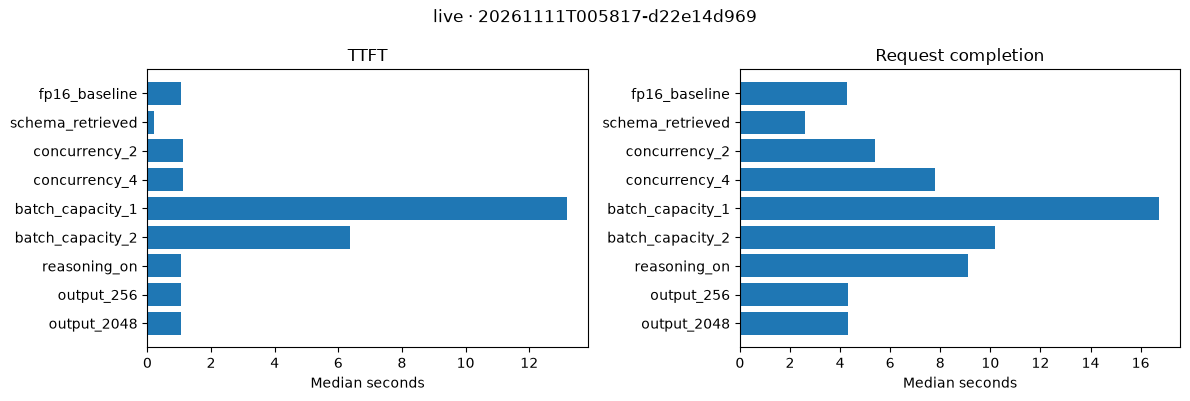

In [38]:
from clinical_trial_mvp.tutorial.session_figures import figure
fig = figure(study)
if fig is not None:
    display(fig)
    import matplotlib.pyplot as plt
    plt.close(fig)
else:
    print('No measured rows available for a figure.')


## 6. Cleanup

Save the notebook to retain genuine Live outputs. Native servers stop after each row. Stop the owned NIM container (if applicable) before switching models or pausing. Cleanup is safe to repeat and does not stop external servers.


In [39]:
print(study.close())


Study servers stopped. Saved records and notebook outputs are retained.
